In [1]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data, DataMode
from experiments_helper import (
    build_transformer,
    clip_and_step,
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_identity,
    compute_dist_dict,
    compute_data_condition_numbers,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
####################################
# Train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)

In [10]:
seeds = [0, 1, 2]
n_layers_loops = [10]
model_types = ['layered', 'looped']

hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename)

Run 1/6: seed=0, count=10, type=layered, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
iter 0 | Loss: 5.7650909423828125 | time: 0.024388551712036133 | gradnorm: 13.615009307861328
iter 1 | Loss: 5.322114944458008 | time: 0.02575087547302246 | gradnorm: 12.686443328857422
iter 2 | Loss: 5.527280807495117 | time: 0.025564193725585938 | gradnorm: 12.562421798706055
iter 3 | Loss: 5.178330421447754 | time: 0.02658820152282715 | gradnorm: 12.374987602233887
iter 4 | Loss: 5.132678031921387 | time: 0.0270998477935791 | gradnorm: 12.4869384765625
iter 100 | Loss: 1.1558091640472412 | time: 0.016992807388305664 | gradnorm: 1.4975494146347046
iter 200 | Loss: 0.5305713415145874 | time: 0.02142167091369629 | gradnorm: 2.4775853157043457
[DEBUG] [Norm]: infinite gradient norm at iteration 277.


KeyboardInterrupt: 

In [7]:
loss_dict = compute_loss_dict(hist_dict, test_seed=TEST_SEED)

(0, 2, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=loop

In [8]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

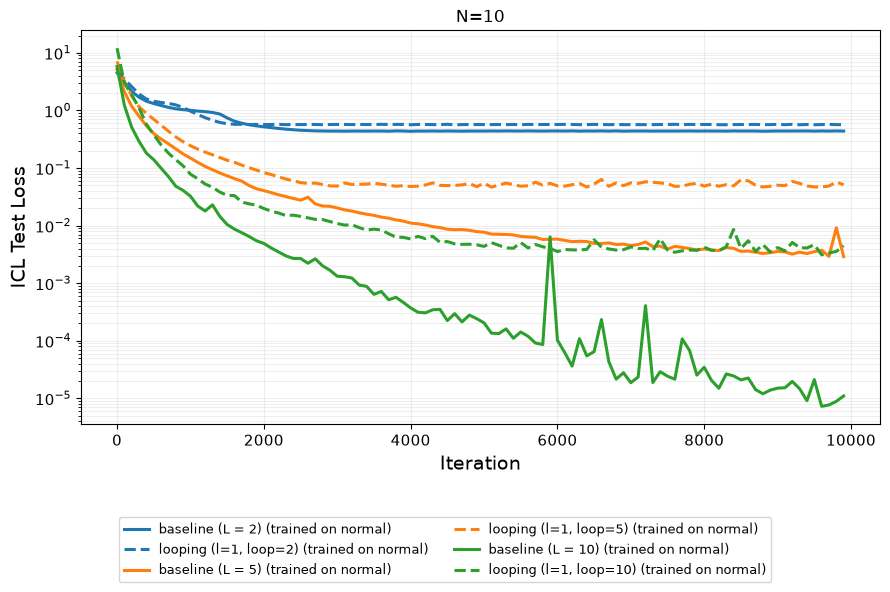

In [9]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

In [ ]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [38]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

NameError: name 'hist_dict' is not defined

In [37]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)

NameError: name 'dist_dict' is not defined

Run 1/15: seed=0, count=5, type=looped, N=2
iter 0 | Loss: 8.224090576171875 | time: 0.01871800422668457 | gradnorm: 23.256296157836914
iter 1 | Loss: 8.118857383728027 | time: 0.014403581619262695 | gradnorm: 24.073047637939453
iter 2 | Loss: 7.912059783935547 | time: 0.015526533126831055 | gradnorm: 22.307273864746094
iter 3 | Loss: 7.685257911682129 | time: 0.015527725219726562 | gradnorm: 22.58423614501953
iter 4 | Loss: 7.724087715148926 | time: 0.015107393264770508 | gradnorm: 20.857467651367188
iter 100 | Loss: 4.103839874267578 | time: 0.01510763168334961 | gradnorm: 13.311128616333008
iter 200 | Loss: 3.285475254058838 | time: 0.014558792114257812 | gradnorm: 4.286308288574219
iter 300 | Loss: 3.0148446559906006 | time: 0.012174367904663086 | gradnorm: 1.0014686584472656
iter 400 | Loss: 2.988403558731079 | time: 0.013481855392456055 | gradnorm: 0.7710242867469788
iter 500 | Loss: 2.9737586975097656 | time: 0.015573740005493164 | gradnorm: 0.573298990726471
iter 600 | Loss: 2.

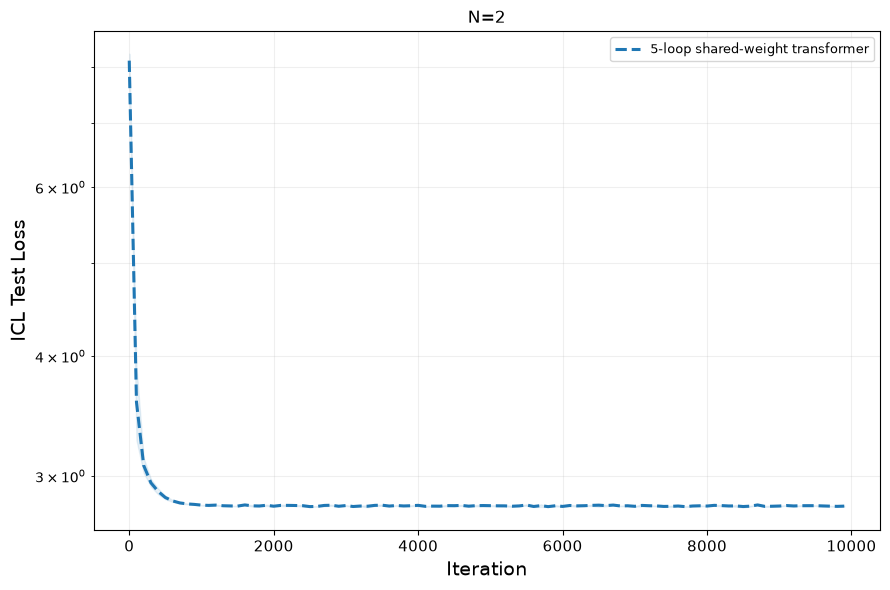

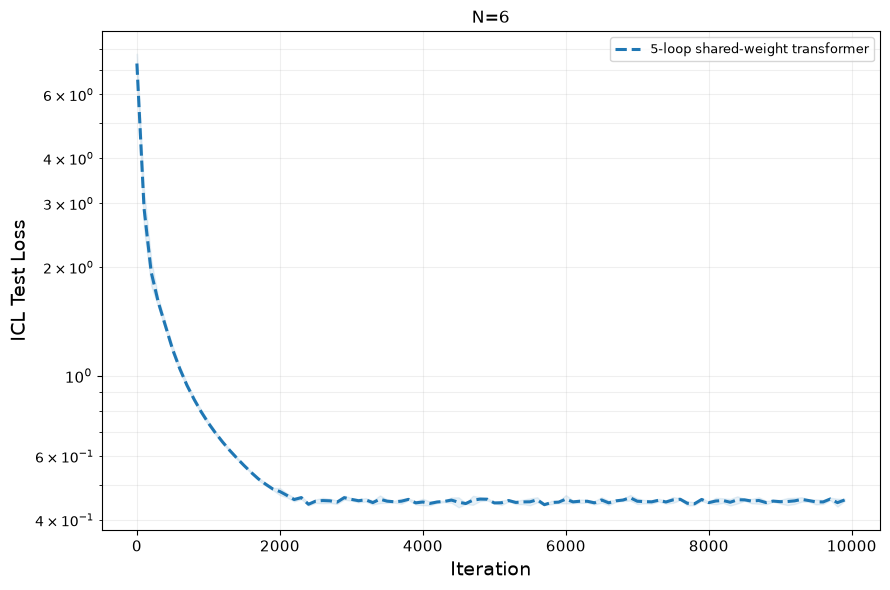

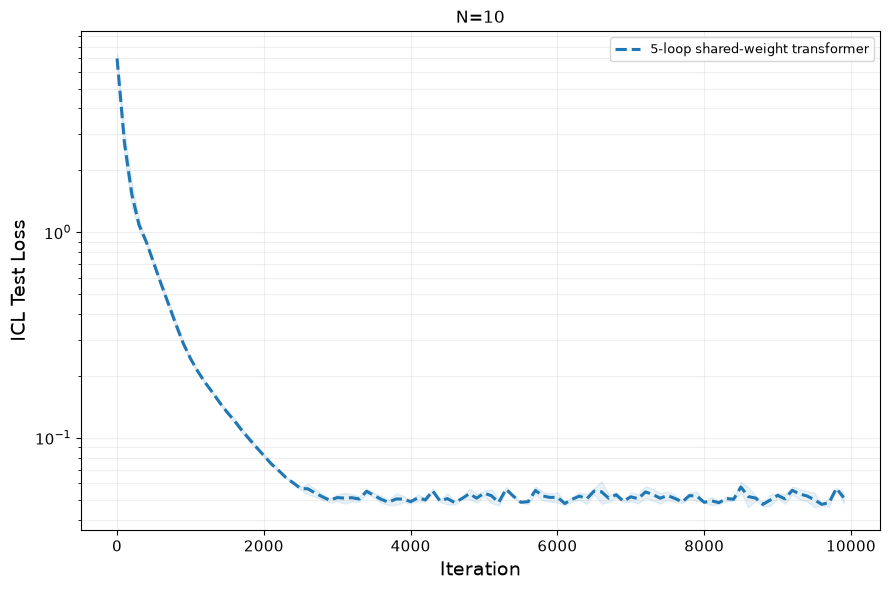

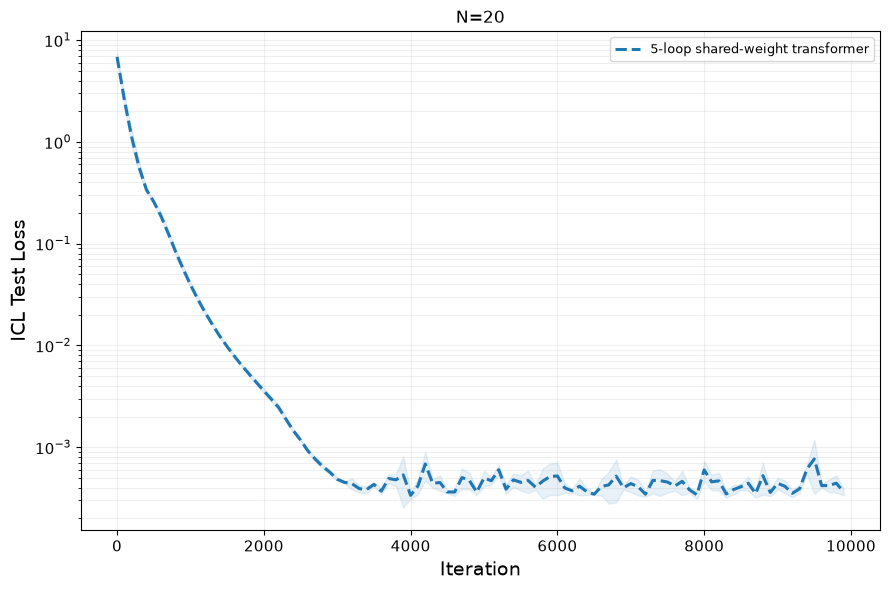

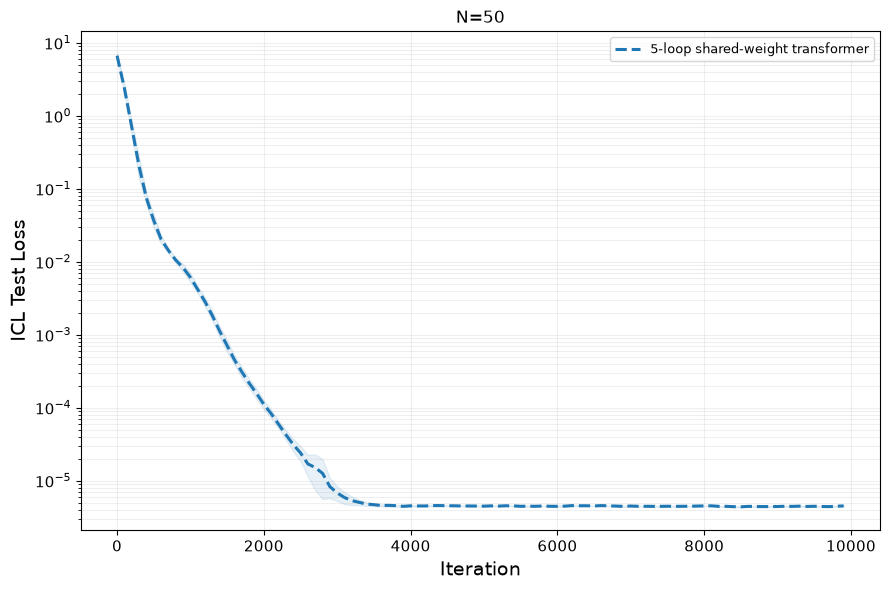

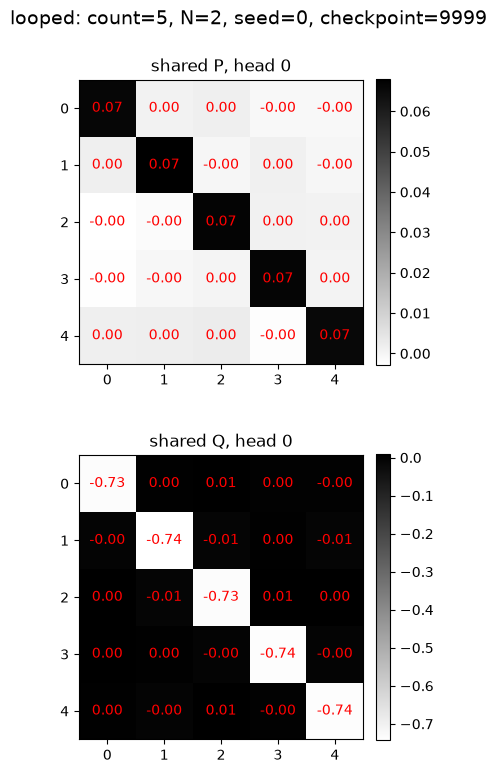

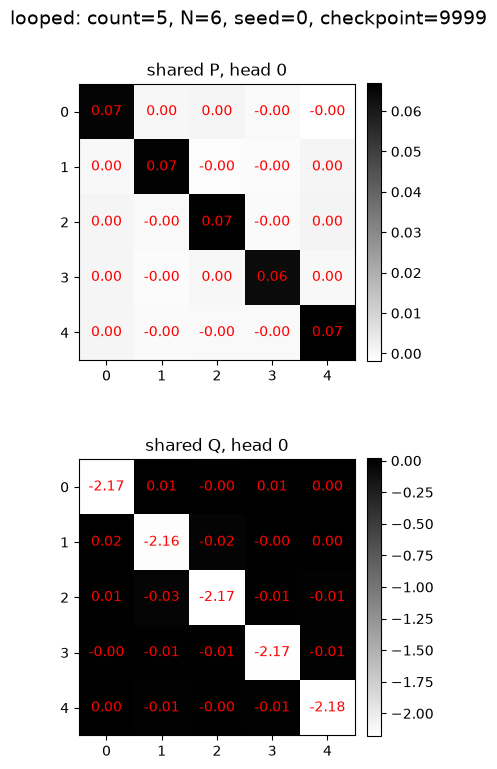

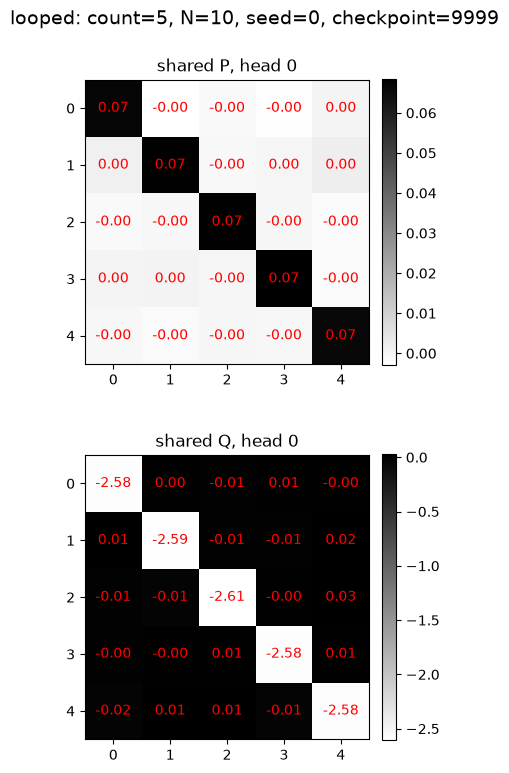

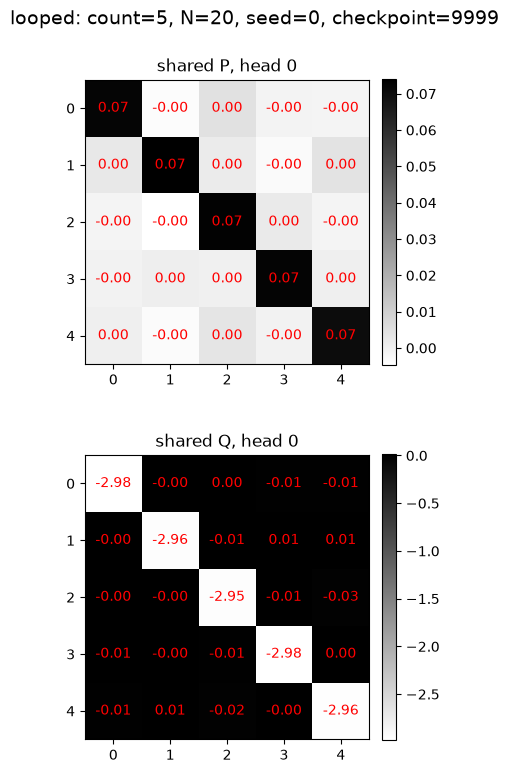

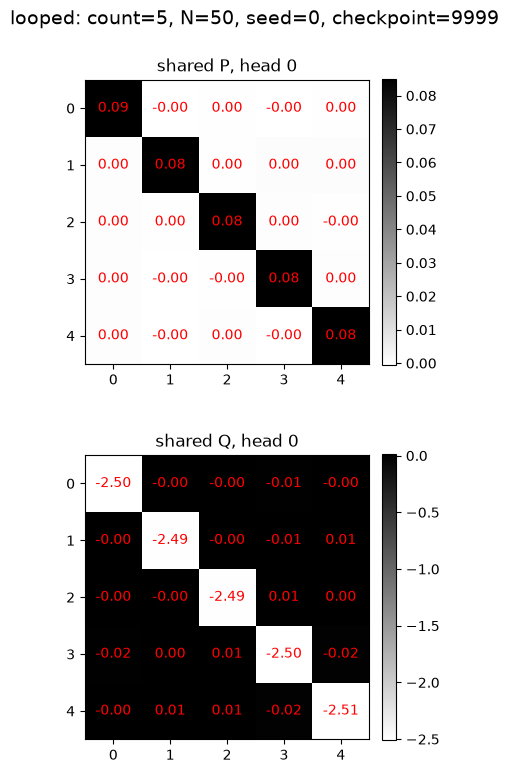

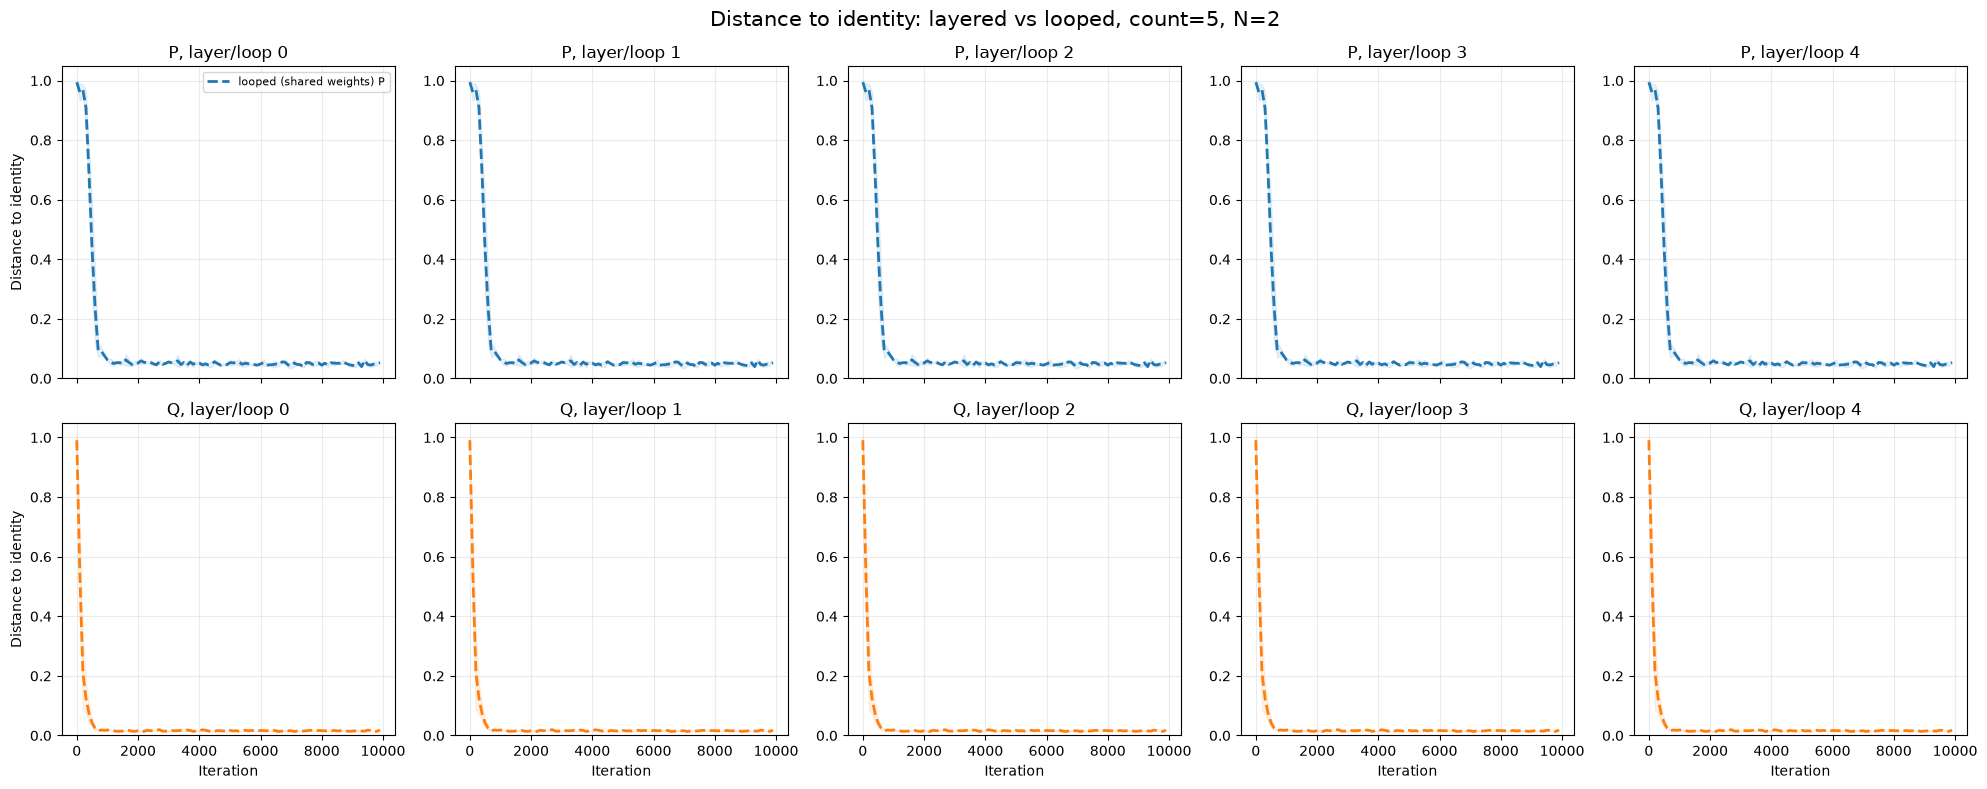

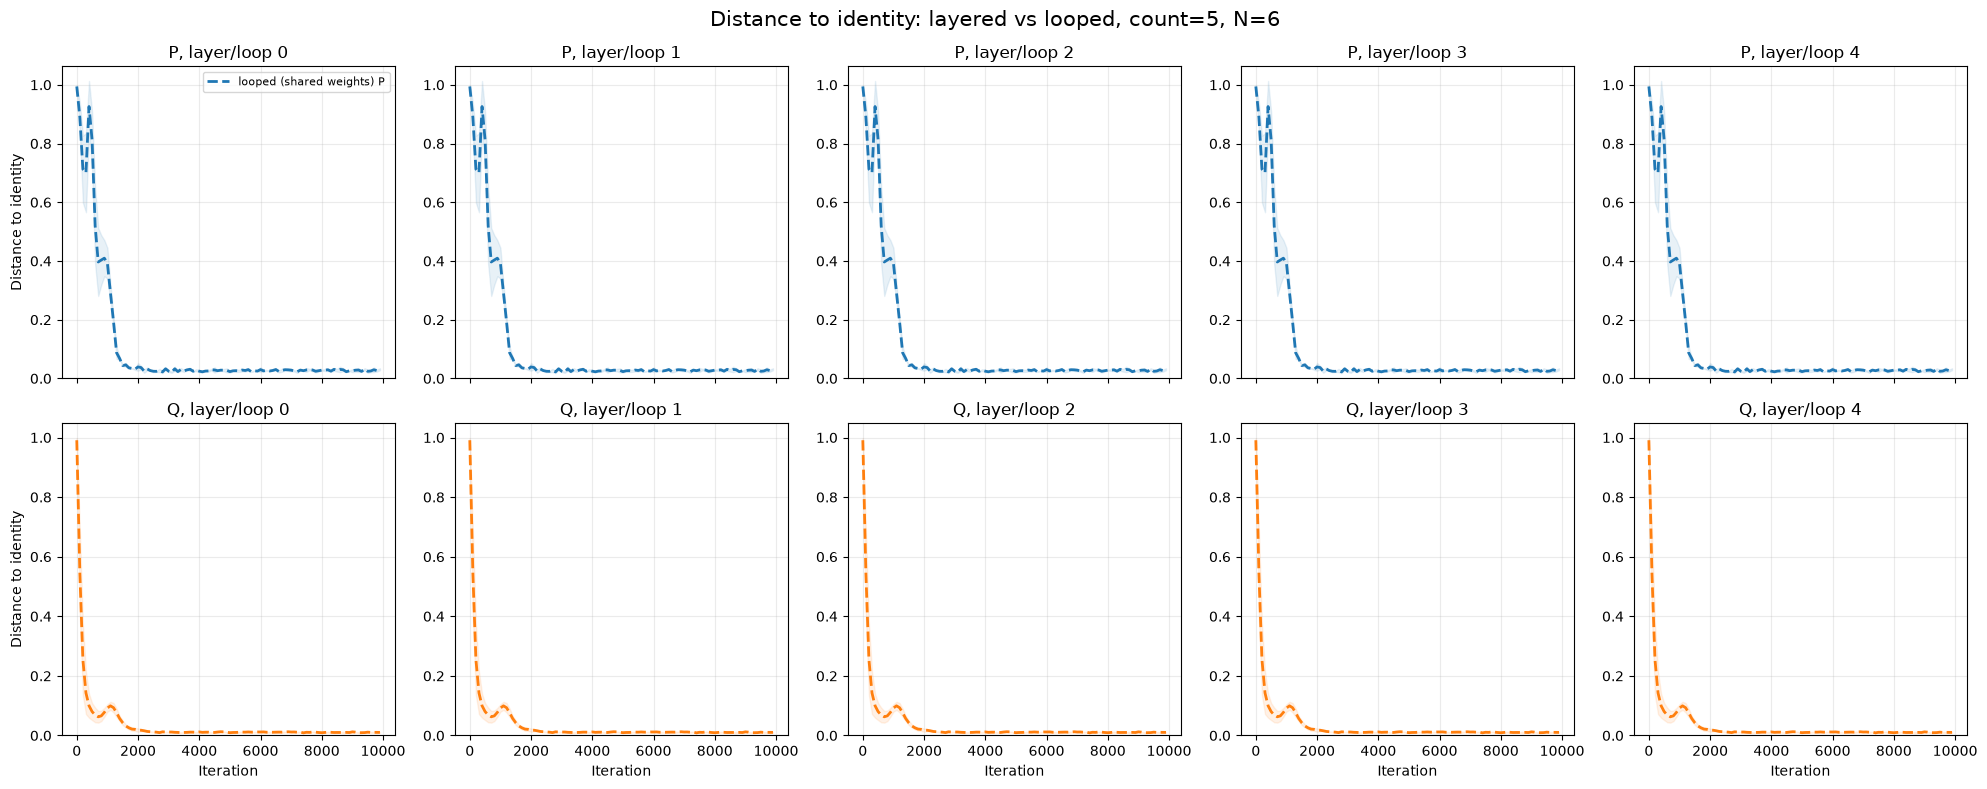

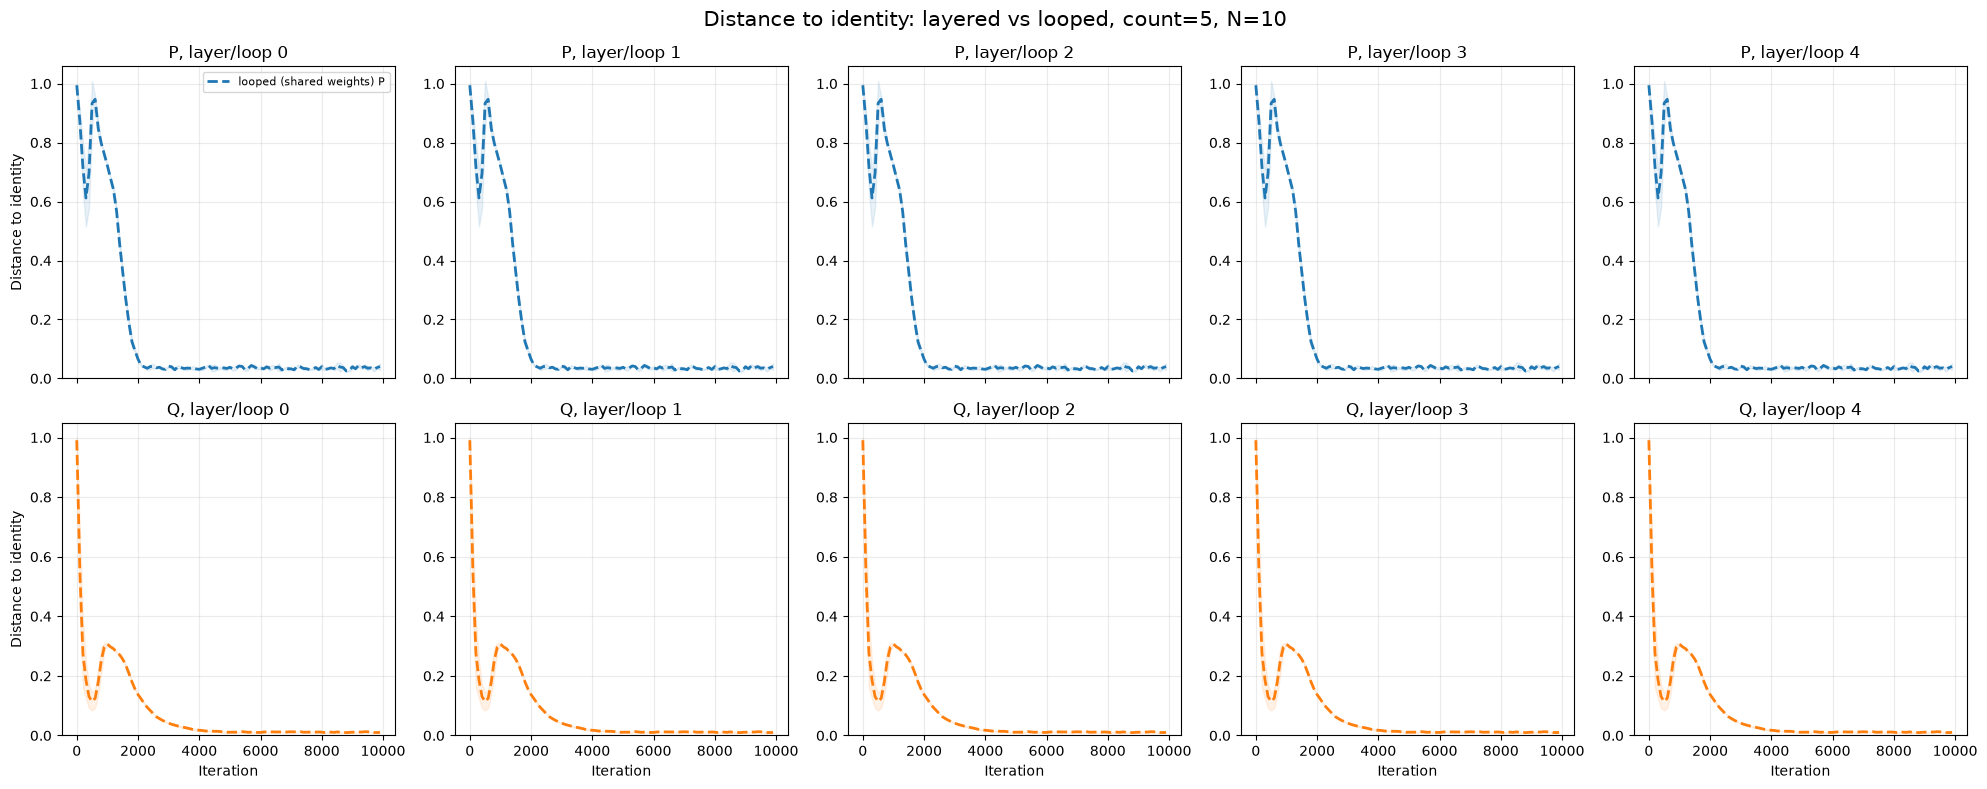

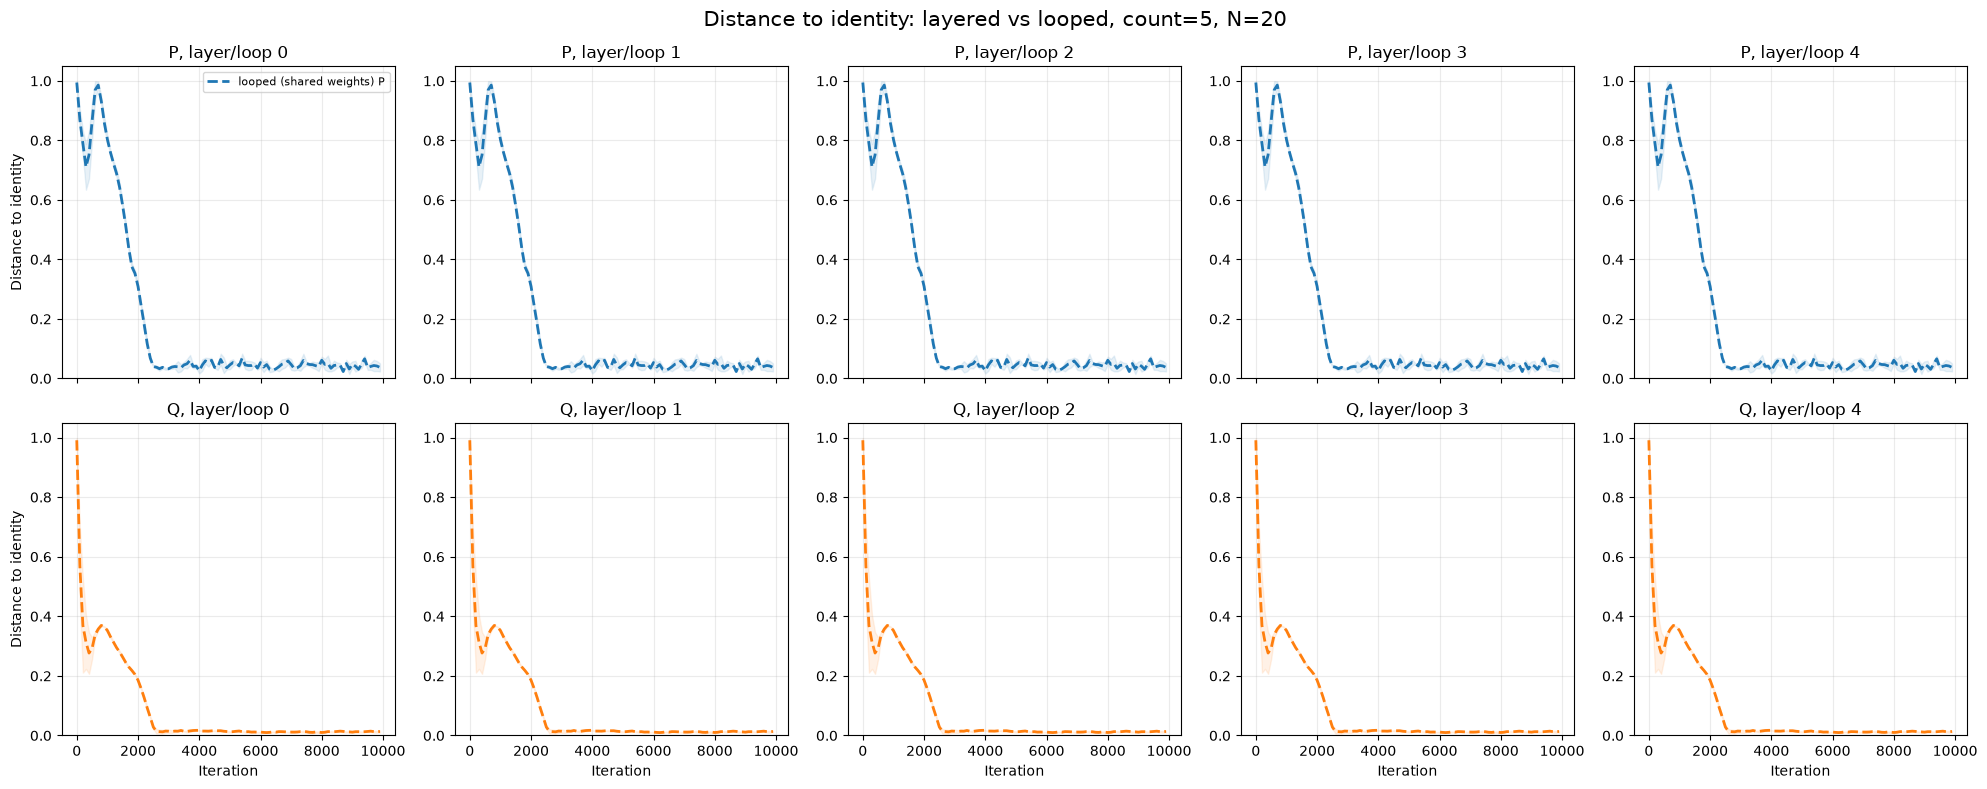

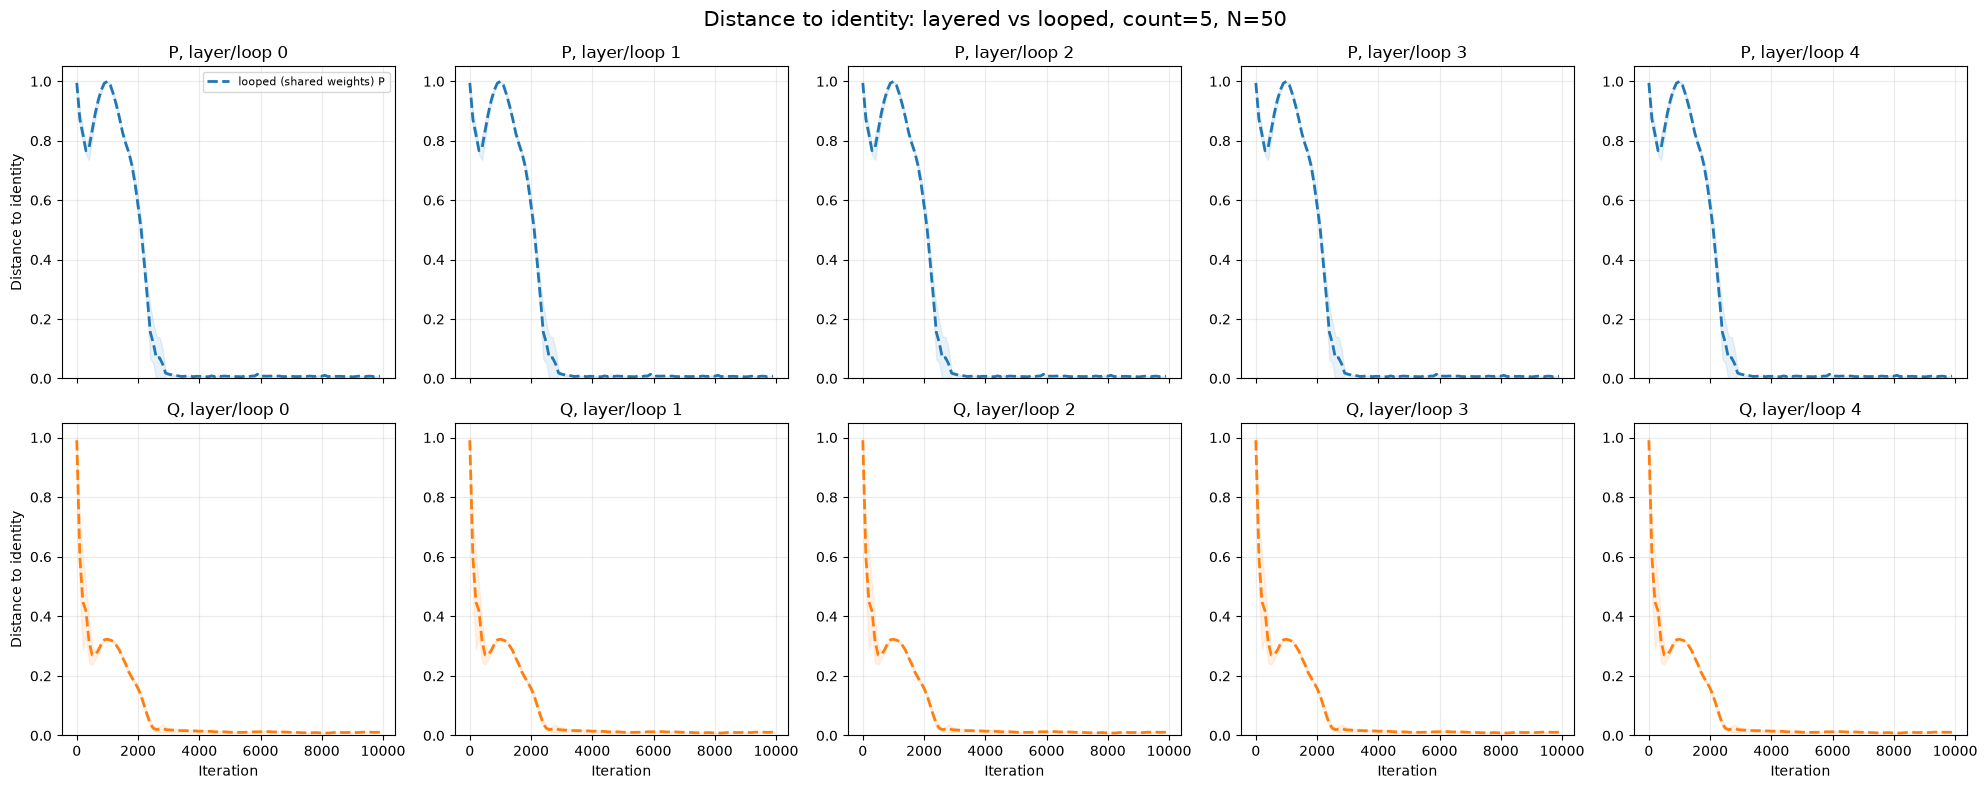

In [ ]:
# Figure 1 computations: looped transformers across context lengths.
f1_seeds = [0, 1, 2]
fig2_N_values = [2, 6, 10, 20, 50]
f1_loop_counts = [5]
f1_model_types = ['looped']
f1_filename = cur_dir + '/figure_one_looped_{}.pth'.format(d)
f1_fig_dir = os.path.join('figures', 'figure_one')
os.makedirs(f1_fig_dir, exist_ok=True)

f1_hist = run_experiment_suite(
    f1_seeds, f1_loop_counts, f1_model_types, f1_filename, context_lengths=fig2_N_values)
f1_loss = compute_loss_dict(f1_hist)
f1_dist = compute_dist_dict(f1_hist, iterations, n_head, hist_stride=hist_stride)

In [ ]:
# Figure 1 plots, immediately following the computation cell.
plot_loss_curves(
    f1_loss,
    f1_loop_counts,
    f1_model_types,
    iterations,
    fig_dir=f1_fig_dir,
    filename='figure_one_test_loss.pdf',
)
plot_parameter_matrices(
    f1_hist,
    f1_seeds[0],
    f1_loop_counts,
    f1_model_types,
    n_head,
    hist_stride=hist_stride,
    fig_dir=f1_fig_dir,
)
plot_dist_to_identity(
    f1_dist,
    f1_loop_counts,
    iterations,
    fig_dir=f1_fig_dir,
)

In [15]:
# Train on the notebook's standard identity-covariance data, then evaluate on
# the adjusted (rotated and rescaled) covariate distribution.
# Reuse run_experiment_suite, compute_loss_dict, and compute_dist_dict.

oos_seeds = [0, 1, 2]
oos_counts = [2, 5]
oos_model_types = ['looped']
oos_fig_dir = os.path.join('figures', 'identity_train_adjusted_test')
os.makedirs(oos_fig_dir, exist_ok=True)
oos_filename = os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}.pth')

# Fixed test-time covariance Sigma = U D^2 U^T; training remains unchanged
# and uses generate_data without U,D, i.e. identity covariance.
if d != 5:
    raise ValueError('This covariance setup is defined for d=5.')
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(d, d, device=device)) - 1
U_test = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_test = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

# Train 2/5-loop transformers with the existing training routine.
oos_hist_dict = run_experiment_suite(
    oos_seeds,
    oos_counts,
    oos_model_types,
    oos_filename,
    context_lengths=[N],
)

# Compute test loss versus training iteration and parameter distances before plotting.
oos_loss_dict = compute_loss_dict(
    oos_hist_dict,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)
oos_iterations = np.arange(0, max_iters, stride)
oos_dist_dict = compute_dist_dict(
    oos_hist_dict,
    oos_iterations,
    n_head,
    hist_stride=hist_stride,
)

torch.save(
    {
        'hist_dict': oos_hist_dict,
        'loss_dict': oos_loss_dict,
        'distance_dict': oos_dist_dict,
        'U_test': U_test.detach().cpu(),
        'D_test': D_test.detach().cpu(),
        'seeds': oos_seeds,
        'counts': oos_counts,
        'model_types': oos_model_types,
        'context_length': N,
    },
    os.path.join(cur_dir, f'identity_train_adjusted_test_N{N}_d{d}_results.pth'),
)
print(f'Saved adjusted-distribution experiment results in {oos_fig_dir} and {cur_dir}.')

Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1
iter 0 | Loss: 5.184084415435791 | time: 0.2815721035003662 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.005354166030883789 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.004515171051025391 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.004359245300292969 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.005057334899902344 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.005633115768432617 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.005862712860107422 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.005448579788208008 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004598140716552734 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.

In [24]:
# Evaluate final looped checkpoints with 1 through 50 inference loops.
oos_looped_hist_dict = {
    key: history
    for key, history in oos_hist_dict.items()
    if key[2] == 'looped'
}

oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=50,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)


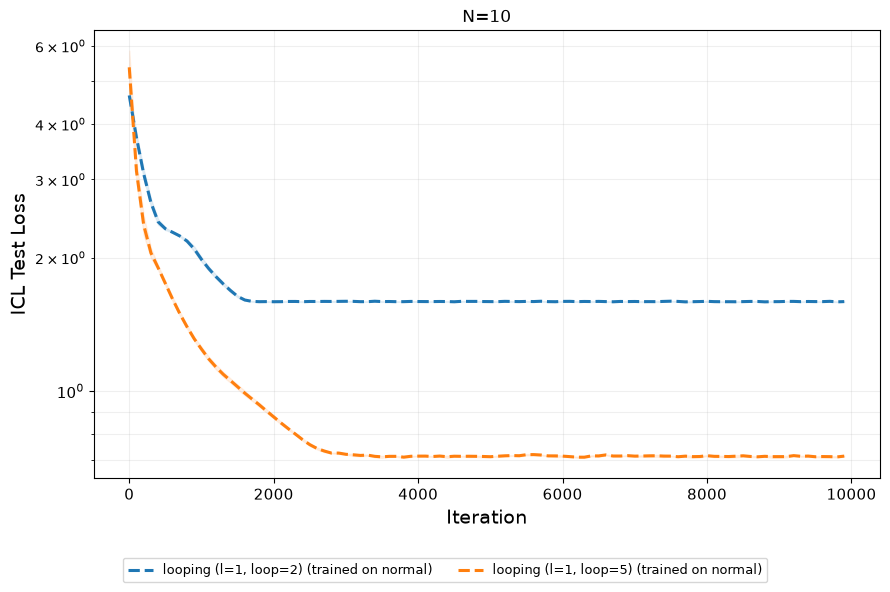

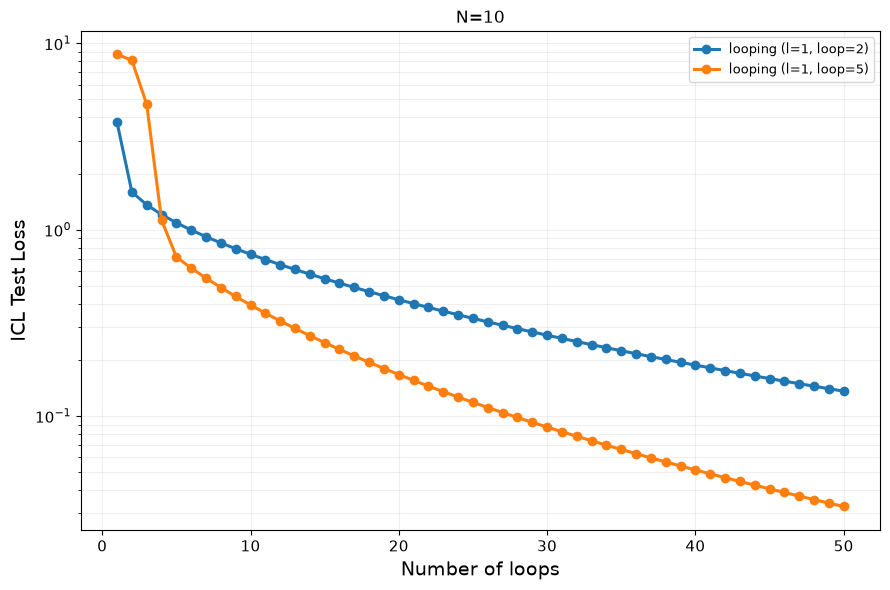

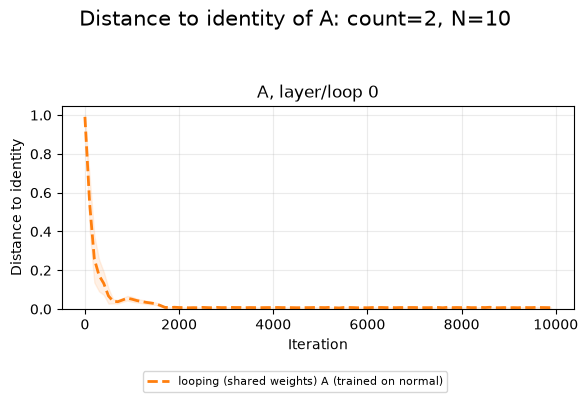

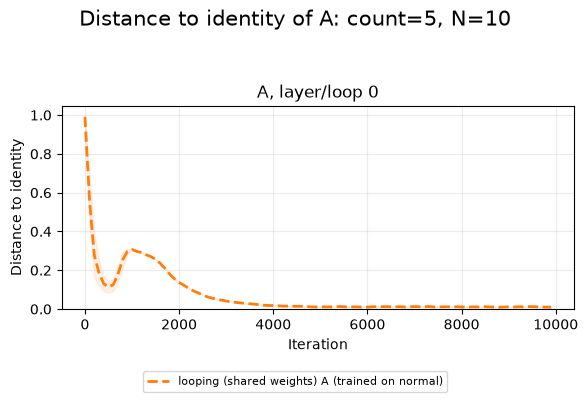

In [25]:
# Plot the adjusted-distribution test loss by training iteration.
plot_loss_curves(
    oos_loss_dict,
    oos_counts,
    oos_model_types,
    oos_iterations,
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_test_loss.pdf',
)

# Plot looped-model test loss against the number of inference loops (1..50).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 51),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_loop_count.pdf',
)

# Plot distance-to-identity for the trained looped-model parameters.
plot_dist_to_identity(
    oos_dist_dict,
    oos_counts,
    oos_iterations,
    fig_dir=oos_fig_dir,
)

(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(1, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
(2, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)


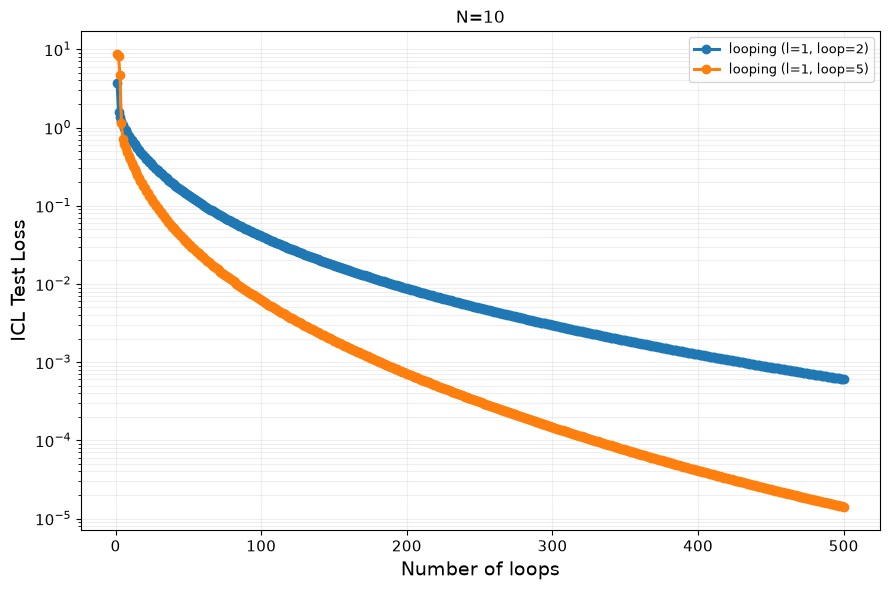

In [26]:
# Sensitivity test: Let's try very large max loop values
oos_loop_loss_dict = compute_looped_loss_by_loop_count(
    oos_looped_hist_dict,
    max_loops=500,
    U=U_test,
    D=D_test,
    test_seed=TEST_SEED,
)

# Plot looped-model test loss against the number of inference loops (1..501).
plot_loop_loss_curves(
    oos_loop_loss_dict,
    n_layers_loops=oos_counts,
    loop_counts=range(1, 501),
    fig_dir=oos_fig_dir,
    filename='adjusted_distribution_loss_vs_extended_loop_count.pdf',
)

# My Custom Experiments

In the previous sections I have attempted to re-produce experiments from Gatmiry et al. In the following sections, I will implement several experiments that apply different assumptions and test the theoretical bounds of this paper. These were not written in the original paper.

## Distribution shift: high-condition-number test data

Train layered and shared-weight looped transformers on standard Gaussian regression tasks with $d=5$ and $N=10$. Evaluate the same checkpoints on fixed, independent standard and transformed test batches. The transformed population covariance has condition number $1000$; individual context Gram matrices have varying condition numbers.

Training and test batch sizes, optimization, initialization, and checkpoint settings are shared with the first experiment. Training uses the repository's clipped `in_context_loss`; the plotted held-out loss is **unclipped** mean squared prediction error. Curves show the mean and standard deviation across training seeds; nonfinite losses are omitted and reported. First run the import, problem-parameter, `run_experiment_suite`, `compute_loss_dict`, and `plot_loss_curves` definition cells above, then run this section in order. Rerun the problem-parameter cell if another experiment has changed its settings.

In [24]:
import math

# Match the first experiment's seeds and architectures, using the requested sizes.
hc_seeds = [0, 1, 2]
hc_sizes = [1, 2, 5, 10]
hc_model_types = ['looped']

# Only the test distribution differs from the first experiment.
hc_cov_condition = 10000.0
hc_rotation_seed = 2000

if N != 10 or d != 5:
    raise ValueError('Run the first experiment\'s problem-parameter cell to set N=10 and d=5.')
print(f'High-condition experiment device: {device}')

High-condition experiment device: cuda


In [92]:
# Reuse the first experiment's training and evaluation settings.
hc_iterations = np.arange(0, max_iters, stride)
hc_fig_dir = os.path.join('figures', 'high_condition_test')
os.makedirs(hc_fig_dir, exist_ok=True)
hc_history_file = os.path.join(cur_dir, 'high_condition_N10_d5_histories.pth')
hc_results_file = os.path.join(cur_dir, 'high_condition_N10_d5_results.pth')

# Generate a fixed orthogonal basis by SVD, with a prescribed covariance spectrum.
torch.manual_seed(hc_rotation_seed)

svd_result = torch.linalg.svd(torch.randn(d, d, device=device))

hc_U = svd_result.U
hc_scales = torch.logspace(
    0, -0.5 * math.log10(hc_cov_condition), d, device=device,
)

hc_D = torch.diag(hc_scales)

print(f'Population covariance condition number: {torch.linalg.cond(hc_D).item() ** 2:.1f}')

Population covariance condition number: 10000.0


Updated todo list

For each normal covariate, `generate_data()` starts with $z \sim \mathcal N(0,I)$ and applies

$$
x = U D z.
$$

Here’s each component’s role:

1. **`hc_scales`** contains standard deviations ranging from $1$ down to $1/\sqrt{1000}$. These set the spread of the data in each principal direction.
2. **`hc_D`** places those scales on a diagonal: $D = \operatorname{diag}(\text{hc_scales})$.
3. **`hc_U`** rotates the scaled data. Because $U$ is orthogonal, it changes the directions but not the condition number.

The resulting **population covariance** is

$$
\Sigma = \operatorname{Cov}(x) = U D^2 U^\top.
$$

Its eigenvalues are the squared entries of `hc_scales`. Therefore, its condition number is

$$
\kappa(\Sigma)
= \frac{\text{largest eigenvalue}}{\text{smallest eigenvalue}}
= \frac{1^2}{(1/\sqrt{1000})^2}
= 1000.
$$

The fixed value applies to the **population covariance**. Each sampled context has only `N = 10` examples, so its empirical covariance will generally have a different condition number.

In [37]:
# Examine a reproducible batch from the high-condition test distribution.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median context Gram condition: {hc_gram_conditions.median().item():.1f}')

NameError: name 'hc_U' is not defined

In [75]:
# Train on standard normal data using the existing training helper.
hc_hist_dict = run_experiment_suite(
    seeds=hc_seeds,
    n_layers_loops=hc_sizes,
    model_types=hc_model_types,
    filename=hc_history_file,
    context_lengths=[N],
)

Run 1/4: seed=0, count=1, type=looped, N=10
iter 0 | Loss: 4.782515525817871 | time: 0.0069239139556884766 | gradnorm: 3.1331946849823
iter 1 | Loss: 4.460882663726807 | time: 0.005681753158569336 | gradnorm: 3.160719156265259
iter 2 | Loss: 4.659054756164551 | time: 0.006200075149536133 | gradnorm: 3.2489049434661865
iter 3 | Loss: 4.460082054138184 | time: 0.005029439926147461 | gradnorm: 3.143481969833374
iter 4 | Loss: 4.543564319610596 | time: 0.004951953887939453 | gradnorm: 3.2081918716430664
iter 100 | Loss: 3.836466073989868 | time: 0.002681732177734375 | gradnorm: 3.024074077606201
iter 200 | Loss: 3.3473775386810303 | time: 0.0026710033416748047 | gradnorm: 2.7464020252227783
iter 300 | Loss: 2.8352458477020264 | time: 0.0026853084564208984 | gradnorm: 2.3970413208007812
iter 400 | Loss: 2.3862922191619873 | time: 0.0027616024017333984 | gradnorm: 1.8073077201843262
iter 500 | Loss: 2.0302138328552246 | time: 0.002690553665161133 | gradnorm: 1.1721309423446655
iter 600 | Los

In [ ]:
# Compare both distributions using the first experiment's fixed test seed and batch size.
hc_standard_loss = compute_loss_dict(
    hc_hist_dict, test_seed=TEST_SEED
)
hc_shifted_loss = compute_loss_dict(
    hc_hist_dict, U=hc_U, D=hc_D, test_seed=TEST_SEED
)

# Verify the actual condition numbers of the held-out context matrices.
torch.manual_seed(TEST_SEED)
hc_Z, _ = generate_data(normal_data_mode, N, d, B, U=hc_U, D=hc_D)
hc_data_conditions, hc_gram_conditions = compute_data_condition_numbers(hc_Z)
print(f'Median empirical context X condition: {hc_data_conditions.median().item():.1f}')
print(f'Median empirical context Gram condition: {hc_gram_conditions.median().item():.1f}')
for name, losses in [('standard', hc_standard_loss), ('shifted', hc_shifted_loss)]:
    n_nonfinite = sum((~torch.isfinite(values)).sum().item() for values in losses.values())
    print(f'{name} test: {n_nonfinite} missing or nonfinite checkpoint losses')

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head, 'mode': normal_data_mode,
        'shape_k': 0.1, 'alg': alg, 'lr': lr, 'clip_r': clip_r,
        'var': var, 'max_iters': max_iters, 'hist_stride': hist_stride,
        'stride': stride, 'seeds': hc_seeds, 'sizes': hc_sizes,
        'model_types': hc_model_types, 'test_seed': TEST_SEED,
        'cov_condition': hc_cov_condition, 'rotation_seed': hc_rotation_seed,
    },
    'history_file': hc_history_file,
    'standard_loss': hc_standard_loss,
    'shifted_loss': hc_shifted_loss,
    'U': hc_U.cpu(),
    'D': hc_D.cpu(),
    'iterations': hc_iterations,
    'context_gram_conditions': hc_gram_conditions.cpu(),
}, hc_results_file)
print(f'Saved results to {hc_results_file}')

Median empirical context Gram condition: 18412.9
standard test: 0 missing or nonfinite checkpoint losses
shifted test: 0 missing or nonfinite checkpoint losses
Saved results to log/high_condition_N10_d5_results.pth


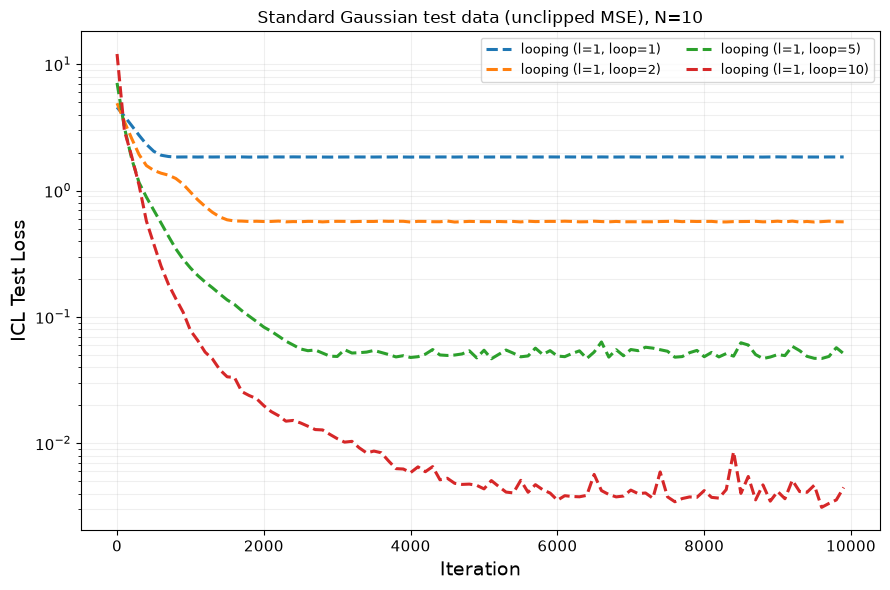

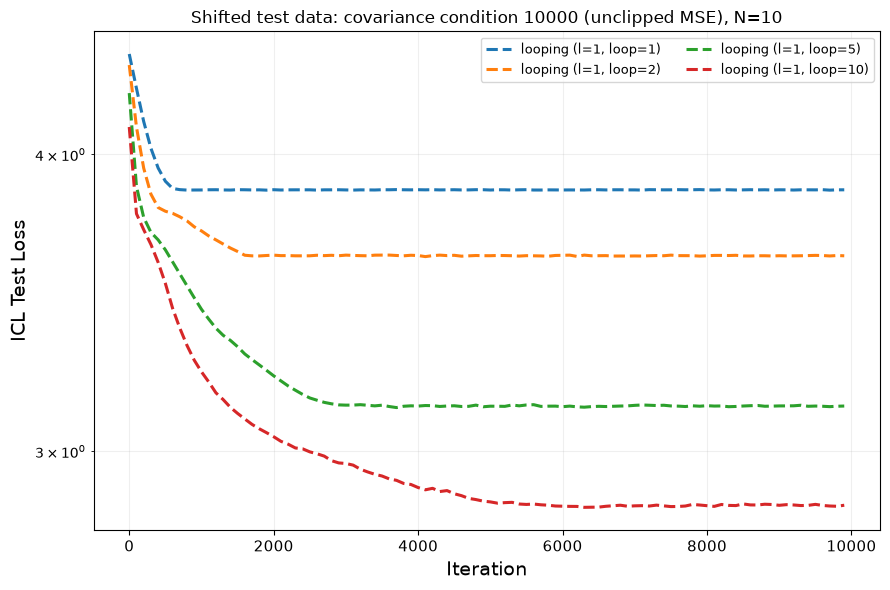

In [77]:
# Plot both test distributions with the existing plotting helper.
plot_loss_curves(
    hc_standard_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='standard_test_loss.pdf',
    title='Standard Gaussian test data (unclipped MSE)',
)
plot_loss_curves(
    hc_shifted_loss, hc_sizes, hc_model_types, hc_iterations,
    fig_dir=hc_fig_dir, filename='high_condition_test_loss.pdf',
    title=f'Shifted test data: covariance condition {hc_cov_condition:.0f} (unclipped MSE)',
)

# Different Data Distributions

Train the shared-weight looped transformers from the first experiment independently on each configured data mode, then evaluate each set of checkpoints on an independently sampled test batch from that same mode. The seeds, loop counts, optimization settings, and model setup match the first experiment; the gamma shape parameter comes from the problem-parameter cell.

In [2]:
# Add data mode as an independent experiment configuration.
gamma_data_mode_low_shape = DataMode("gamma", gamma_shape=0.1, gamma_scale=1)
gamma_data_mode_high_shape = DataMode("gamma", gamma_shape=5, gamma_scale=1)
t_distribution_mode = DataMode("t", t_degrees_freedom=5)

seeds = [0, 1, 2]
loop_counts = [1, 2, 5, 10]
model_types = ['looped']
context_lengths = [N]
data_modes = [normal_data_mode, gamma_data_mode_low_shape, gamma_data_mode_high_shape, t_distribution_mode]
iterations = np.arange(0, max_iters, stride)

gamma_fig_dir = os.path.join('figures', 'data_mode_comparison')
os.makedirs(gamma_fig_dir, exist_ok=True)

gamma_history_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_histories.pth')
gamma_results_file = os.path.join(
    cur_dir, f'data_modes_normal_gamma_N{N}_d{d}_results.pth')

gamma_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=gamma_history_file,
    context_lengths=context_lengths,
    data_modes=data_modes,
)

gamma_loss_dict = {
    test_data_mode: compute_loss_dict(
        gamma_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in data_modes
}
# Parameter distances depend on the trained checkpoints, not on the test data mode.
gamma_dist_dict = compute_dist_dict(
    gamma_hist_dict, iterations, n_head, hist_stride=hist_stride)


NameError: name 'DataMode' is not defined

Saved data-mode experiment results to log/data_modes_normal_gamma_N10_d5_results.pth


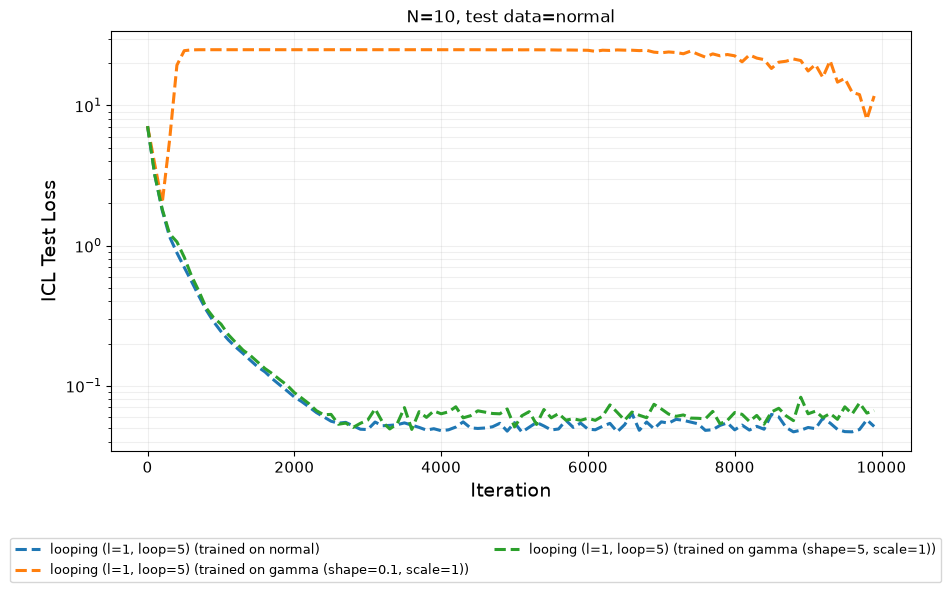

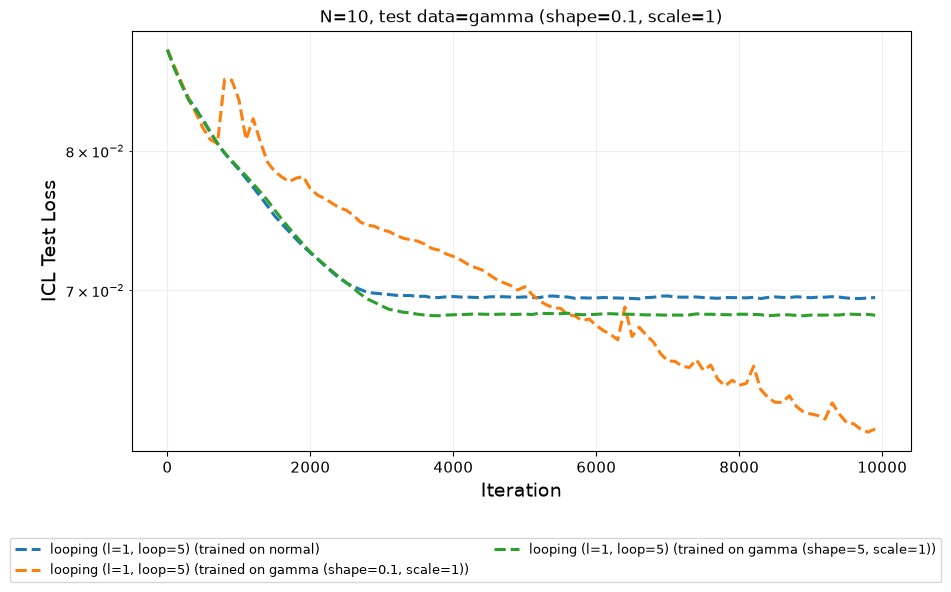

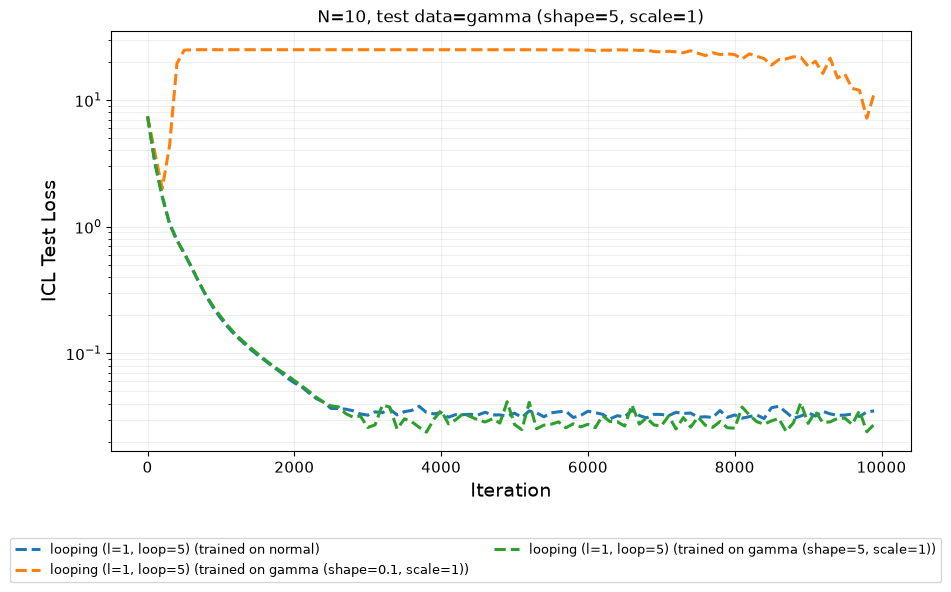

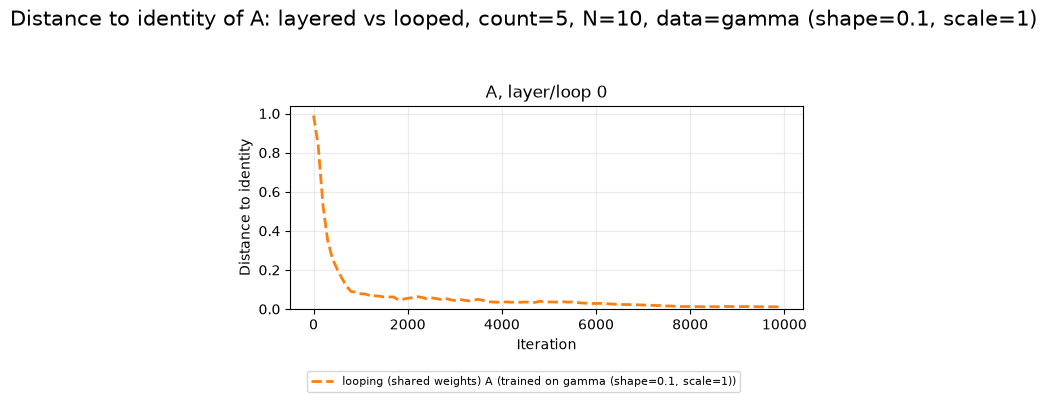

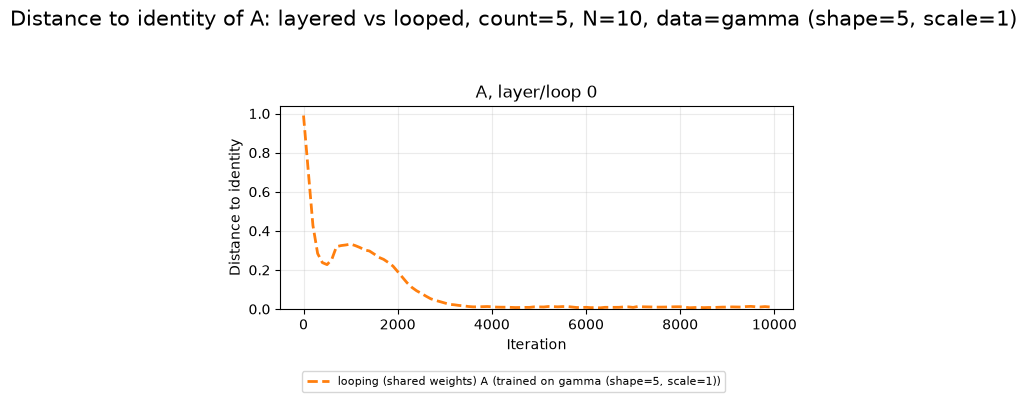

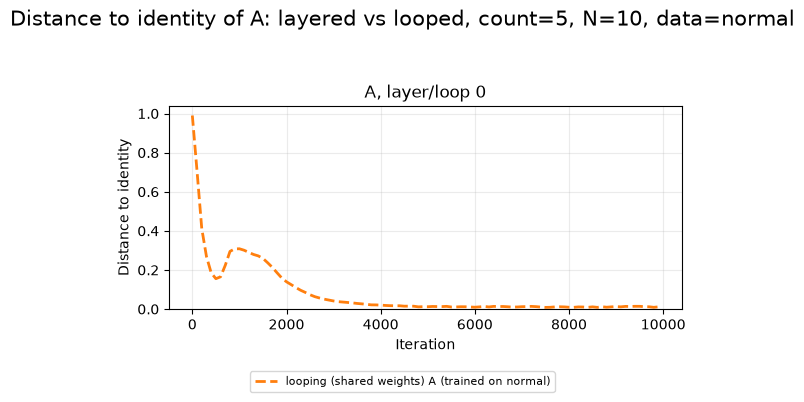

In [23]:
torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': gamma_history_file,
    'hist_dict': gamma_hist_dict,
    'loss_dict_by_test_mode': gamma_loss_dict,
    'distance_dict': gamma_dist_dict,
    'iterations': iterations,
}, gamma_results_file)
print(f'Saved data-mode experiment results to {gamma_results_file}')

for test_data_mode, loss_dict in gamma_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=gamma_fig_dir, filename='data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    gamma_dist_dict, loop_counts, iterations, fig_dir=gamma_fig_dir,
)
plot_parameter_matrices(
    gamma_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=gamma_fig_dir,
)


# Non-Linear Distribution Test

Train the shared-weight looped transformers independently on normal, ReLU-generated, and MLP-generated data. This mirrors the different-distribution experiment: the same seeds, loop counts, optimization settings, and plots are reused to check whether the training converges and to display the learned parameter trajectories.


In [14]:
relu_data_mode = DataMode("relu")
mlp_data_mode = DataMode("mlp")

seeds = [0]
loop_counts = [2, 5, 10]
model_types = ['looped']
context_lengths = [N]
nonlinear_data_modes = [normal_data_mode, relu_data_mode, mlp_data_mode]
iterations = np.arange(0, max_iters, stride)

nonlinear_fig_dir = os.path.join('figures', 'nonlinear_data_mode_comparison')
os.makedirs(nonlinear_fig_dir, exist_ok=True)

nonlinear_history_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_histories.pth')
nonlinear_results_file = os.path.join(
    cur_dir, f'nonlinear_data_modes_N{N}_d{d}_results.pth')

nonlinear_hist_dict = run_experiment_suite(
    seeds=seeds,
    n_layers_loops=loop_counts,
    model_types=model_types,
    filename=nonlinear_history_file,
    context_lengths=context_lengths,
    data_modes=nonlinear_data_modes,
)

nonlinear_loss_dict = {
    test_data_mode: compute_loss_dict(
        nonlinear_hist_dict,
        test_seed=TEST_SEED,
        data_mode=test_data_mode,
    )
    for test_data_mode in nonlinear_data_modes
}
nonlinear_dist_dict = compute_dist_dict(
    nonlinear_hist_dict, iterations, n_head, hist_stride=hist_stride)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'data_modes': nonlinear_data_modes,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': seeds, 'loop_counts': loop_counts,
        'model_types': model_types, 'test_seed': TEST_SEED,
    },
    'history_file': nonlinear_history_file,
    'hist_dict': nonlinear_hist_dict,
    'loss_dict_by_test_mode': nonlinear_loss_dict,
    'distance_dict': nonlinear_dist_dict,
    'iterations': iterations,
}, nonlinear_results_file)
print(f'Saved non-linear data-mode experiment results to {nonlinear_results_file}')

Run 1/9: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None)
iter 0 | Loss: 5.184084415435791 | time: 0.008438587188720703 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.007271766662597656 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.007939815521240234 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.0077419281005859375 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.007574796676635742 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.0052394866943359375 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.006361246109008789 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.00635838508605957 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.004073381423950195 | gradnorm: 1.5670084953308105
iter 500 | Loss: 1.440165

/home/i4sincla/Documents/projects/cs-886/looped-transformers-gradient-descent/.env/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


iter 0 | Loss: 22.86710548400879 | time: 2.4036972522735596 | gradnorm: 20.595840454101562
iter 1 | Loss: 11.965705871582031 | time: 0.007816553115844727 | gradnorm: 82.57300567626953
iter 2 | Loss: 23.663801193237305 | time: 0.008239269256591797 | gradnorm: 134.87745666503906
iter 3 | Loss: 22.301246643066406 | time: 0.008141279220581055 | gradnorm: 99.23126220703125
iter 4 | Loss: 18.46664047241211 | time: 0.008145332336425781 | gradnorm: 49.724632263183594
iter 100 | Loss: 15.3301362991333 | time: 0.009746551513671875 | gradnorm: 77.91268920898438
iter 200 | Loss: 6.315530776977539 | time: 0.009783744812011719 | gradnorm: 40.39655685424805
iter 300 | Loss: 7.328475475311279 | time: 0.009759187698364258 | gradnorm: 186.7466278076172
iter 400 | Loss: 7.566160678863525 | time: 0.006357908248901367 | gradnorm: 138.25709533691406
iter 500 | Loss: 6.108644008636475 | time: 0.006046772003173828 | gradnorm: 53.359413146972656
iter 600 | Loss: 6.221442699432373 | time: 0.006385087966918945 |

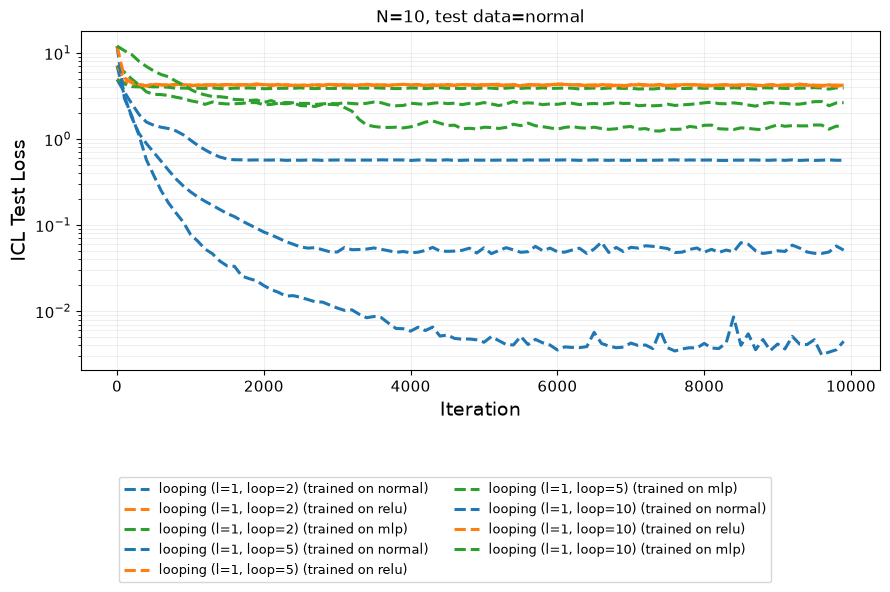

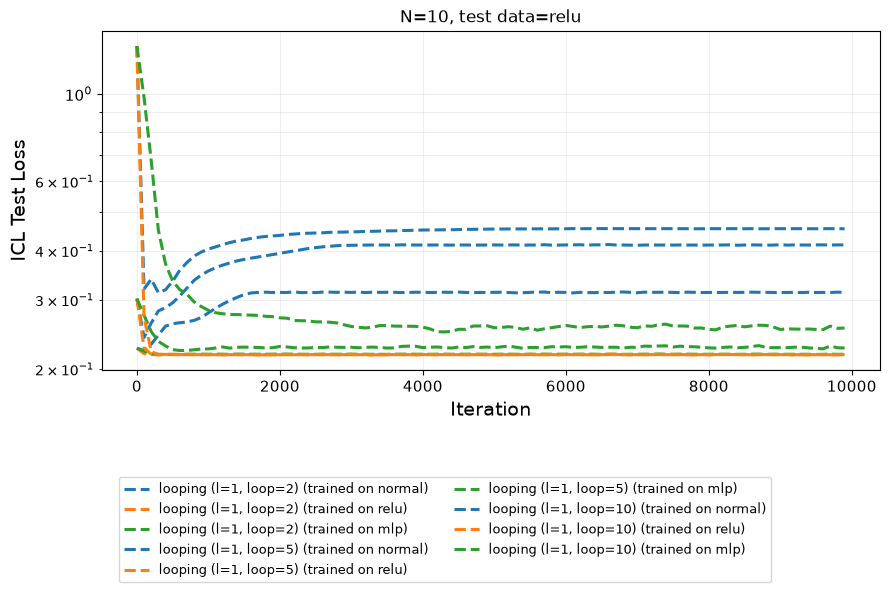

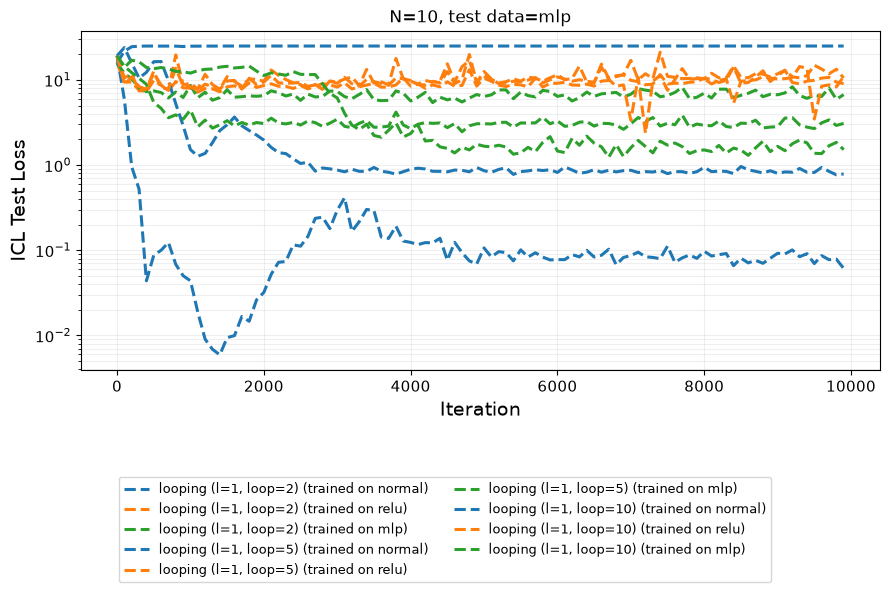

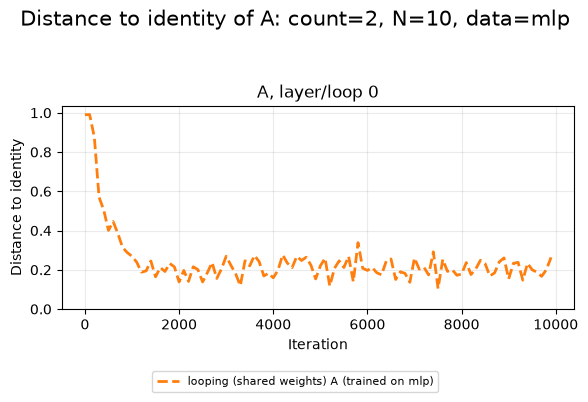

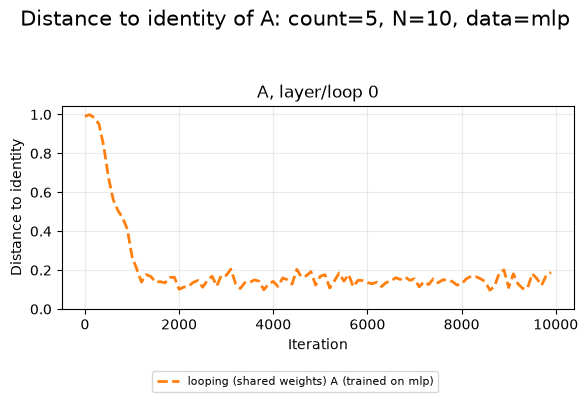

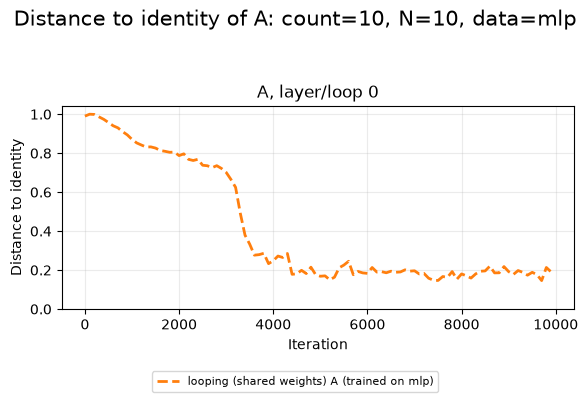

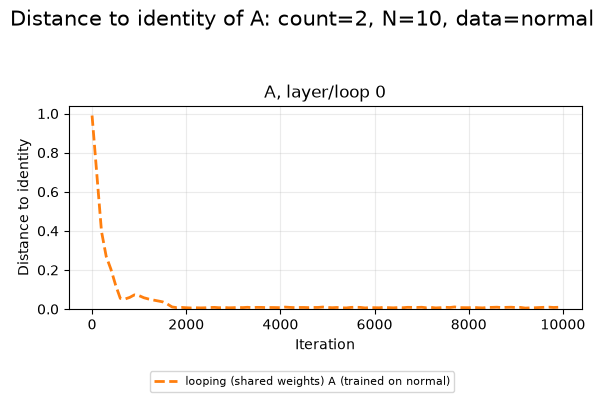

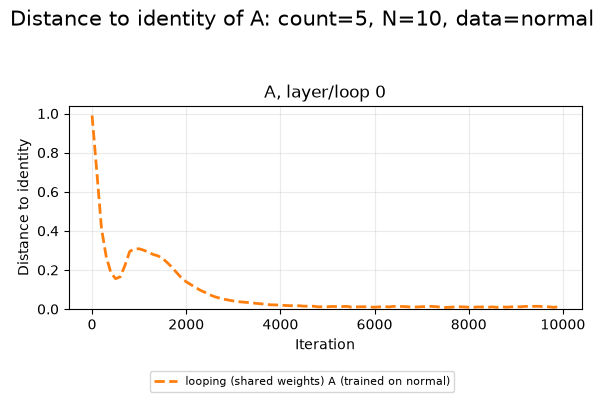

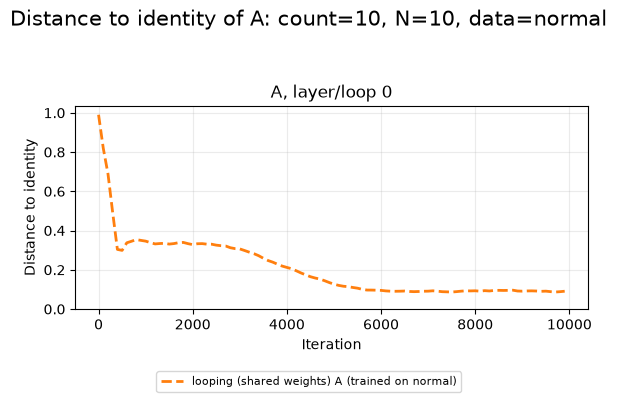

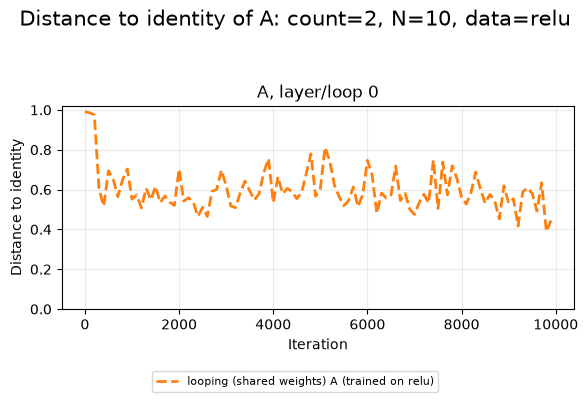

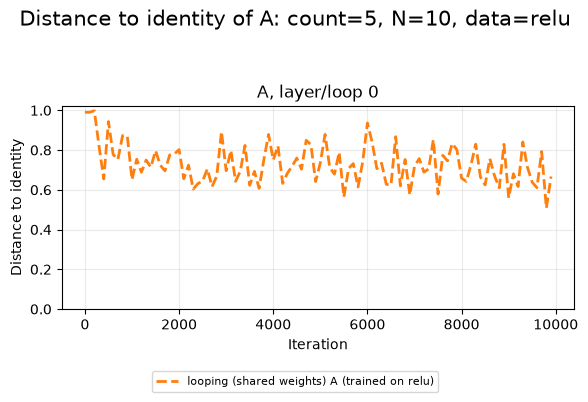

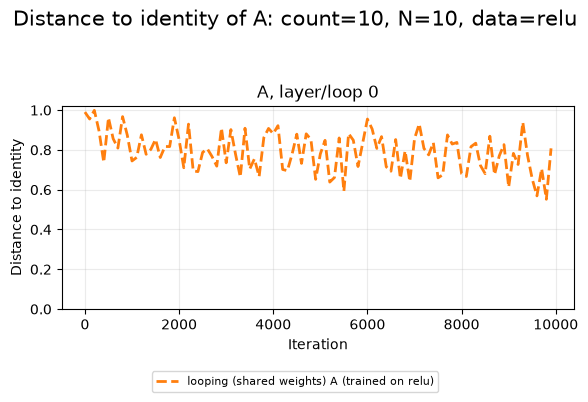

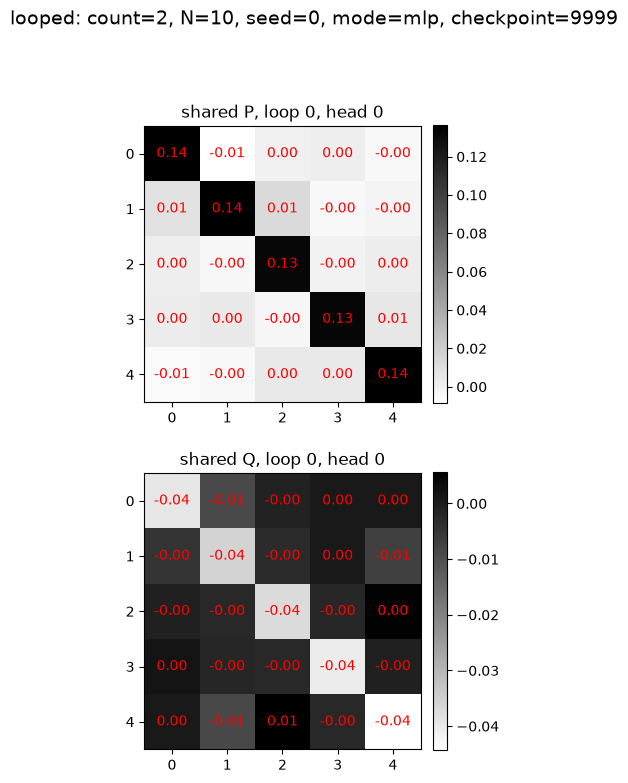

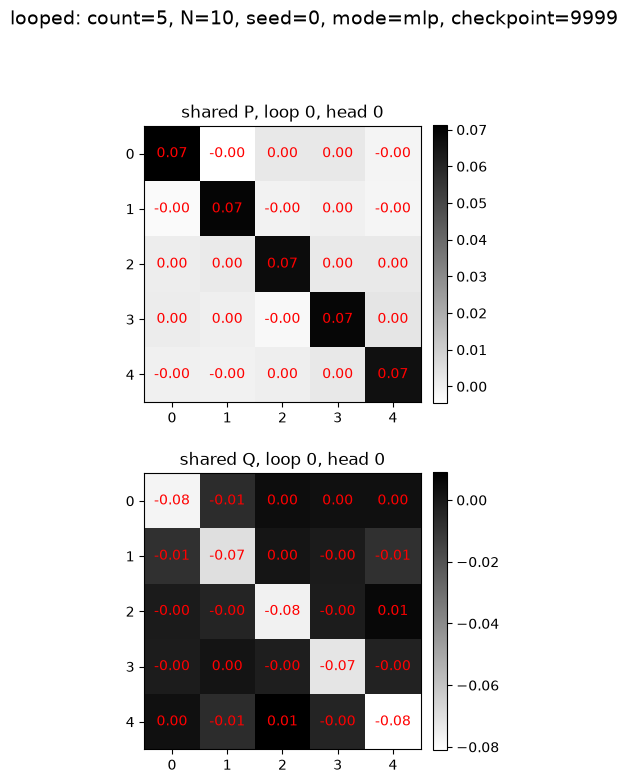

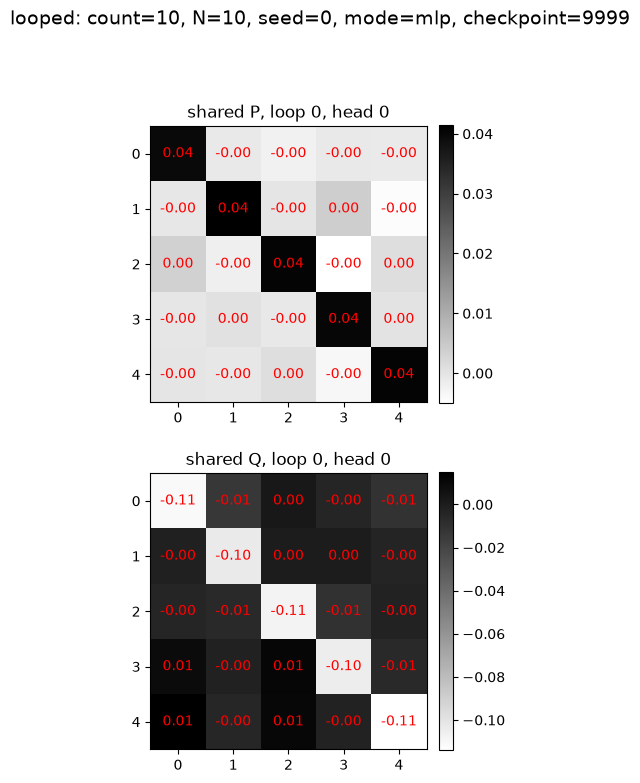

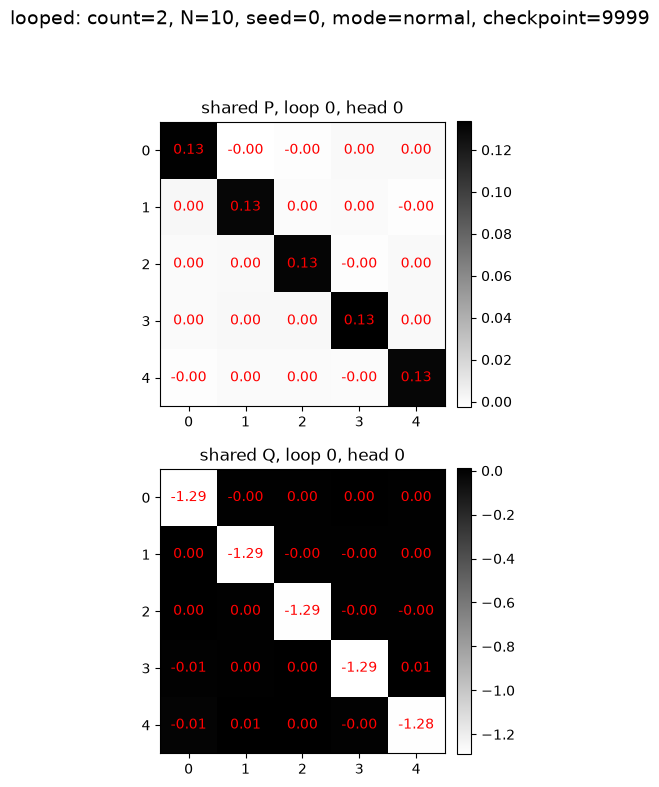

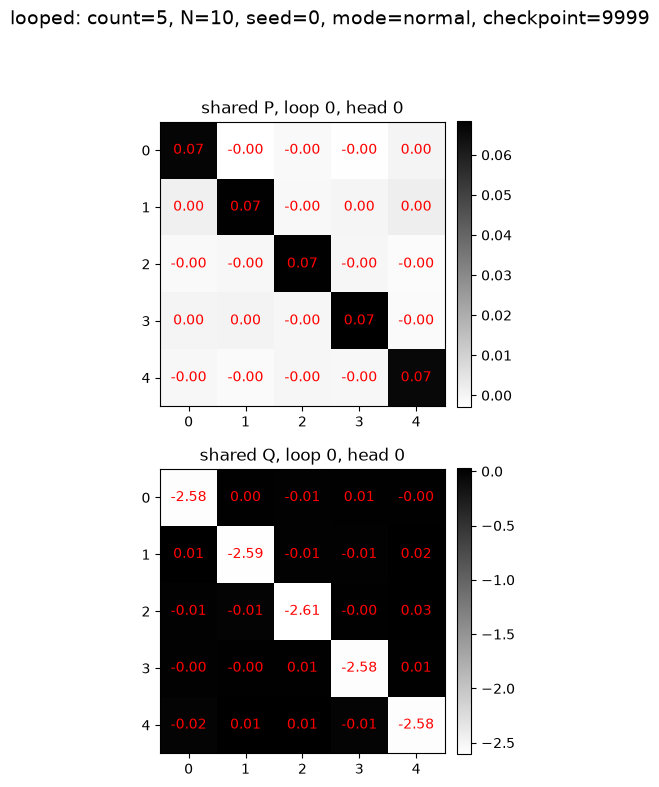

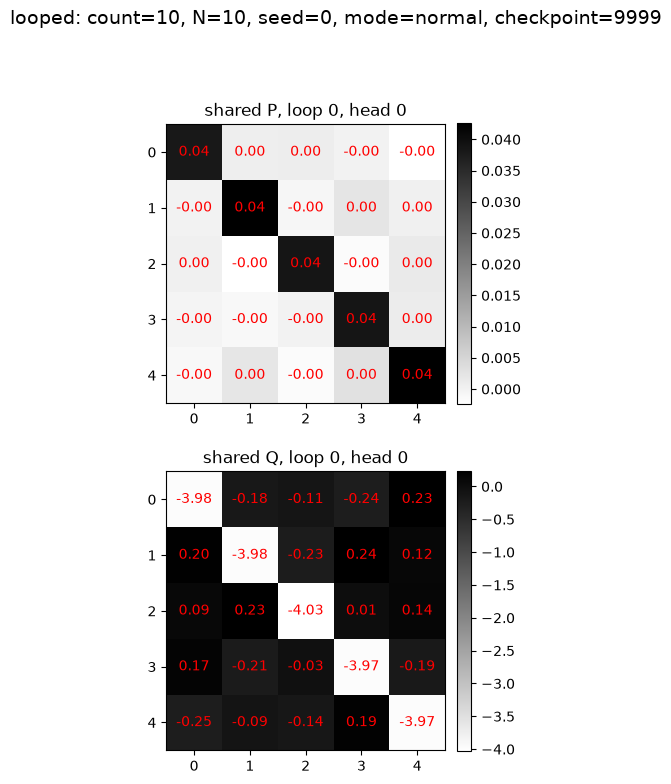

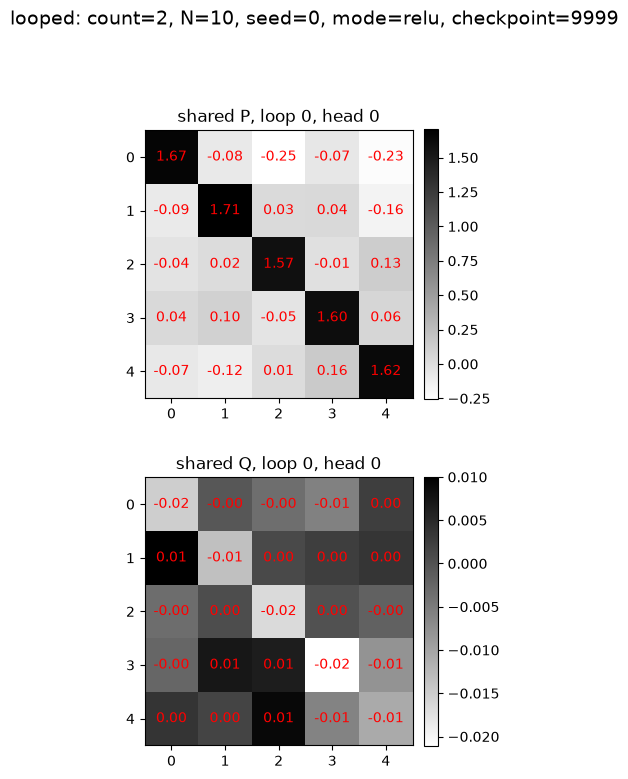

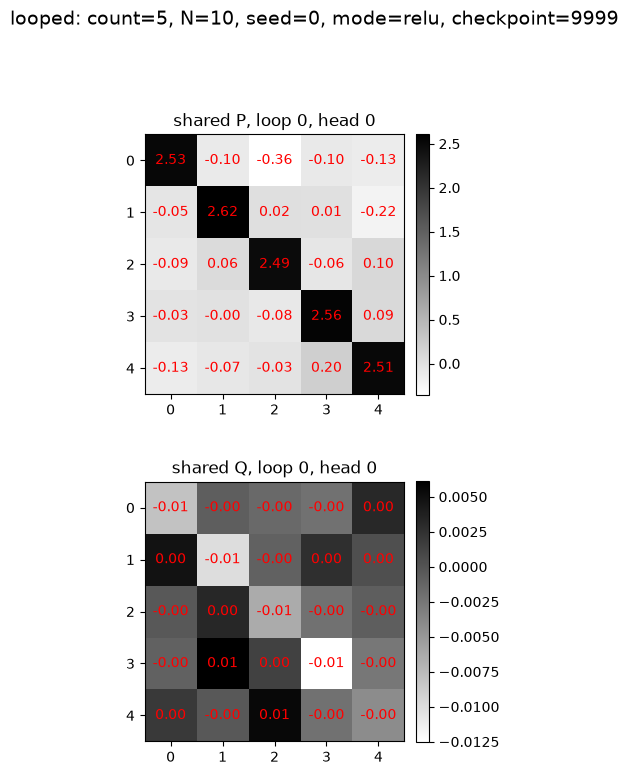

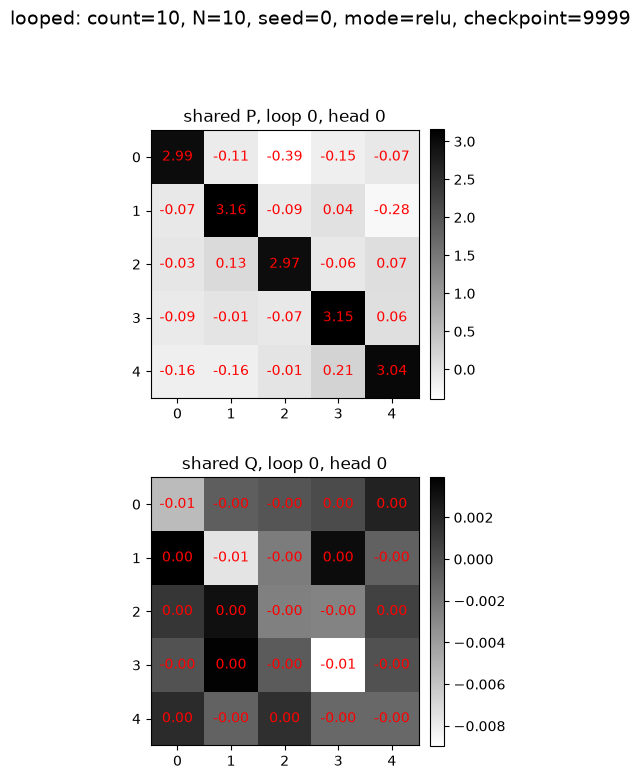

In [15]:
for test_data_mode, loss_dict in nonlinear_loss_dict.items():
    plot_loss_curves(
        loss_dict, loop_counts, model_types, iterations,
        fig_dir=nonlinear_fig_dir,
        filename='nonlinear_data_mode_test_loss.pdf',
        test_data_mode=test_data_mode,
    )
plot_dist_to_identity(
    nonlinear_dist_dict, loop_counts, iterations, fig_dir=nonlinear_fig_dir,
)
plot_parameter_matrices(
    nonlinear_hist_dict, seeds[0], loop_counts, model_types, n_head,
    hist_stride=hist_stride, fig_dir=nonlinear_fig_dir,
)


# Multi-head looped transformer sweep

Train only the shared-weight looped transformer on the same Gaussian regression task while sweeping the number of attention heads over [1, 2, 4, 8]. This mirrors the original depth/loop experiment, but now the architecture is allowed to vary in width instead of type. The run uses the same seeds, loop counts, context length, and training setup as the baseline, and stores the resulting histories and test losses for comparison across head counts.

In [ ]:
# --- Multi-head looped transformer sweep ---

multihead_seeds = [0, 1, 2]
multihead_loop_counts = [2, 5]
multihead_model_types = ['looped']
multihead_head_counts = [1, 2, 4]
multihead_context_lengths = [N]
multihead_filename = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_histories.pth')
multihead_results_file = os.path.join(cur_dir, f'looped_multihead_N{N}_d{d}_results.pth')

multihead_hist_dict = run_experiment_suite(
    seeds=multihead_seeds,
    n_layers_loops=multihead_loop_counts,
    model_types=multihead_model_types,
    filename=multihead_filename,
    context_lengths=multihead_context_lengths,
    data_modes=[normal_data_mode],
    head_counts=multihead_head_counts,
)

multihead_loss_dict = compute_loss_dict(
    multihead_hist_dict,
    test_seed=TEST_SEED,
    data_mode=normal_data_mode,
)

torch.save({
    'config': {
        'N': N, 'd': d, 'B': B, 'n_head': n_head,
        'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
        'max_iters': max_iters, 'hist_stride': hist_stride, 'stride': stride,
        'seeds': multihead_seeds, 'loop_counts': multihead_loop_counts,
        'model_types': multihead_model_types, 'head_counts': multihead_head_counts,
        'context_lengths': multihead_context_lengths, 'data_mode': normal_data_mode,
        'test_seed': TEST_SEED,
    },
    'hist_dict': multihead_hist_dict,
    'loss_dict': multihead_loss_dict,
}, multihead_results_file)

print(f'Saved multi-head looped sweep results to {multihead_results_file}')


Run 1/6: seed=0, count=2, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1
iter 0 | Loss: 5.184084415435791 | time: 0.004908323287963867 | gradnorm: 6.713540554046631
iter 1 | Loss: 4.863616943359375 | time: 0.004140377044677734 | gradnorm: 6.63913631439209
iter 2 | Loss: 5.026864528656006 | time: 0.004330873489379883 | gradnorm: 6.909933567047119
iter 3 | Loss: 4.822576522827148 | time: 0.005481243133544922 | gradnorm: 6.9354119300842285
iter 4 | Loss: 4.920429229736328 | time: 0.004513263702392578 | gradnorm: 7.037217617034912
iter 100 | Loss: 3.4544289112091064 | time: 0.004328012466430664 | gradnorm: 5.220376491546631
iter 200 | Loss: 2.650038242340088 | time: 0.004304170608520508 | gradnorm: 3.9534597396850586
iter 300 | Loss: 1.97808039188385 | time: 0.003993034362792969 | gradnorm: 2.7030904293060303
iter 400 | Loss: 1.5920723676681519 | time: 0.003999948501586914 | gradnorm: 1.5670084953308105
iter 500 | Loss: 

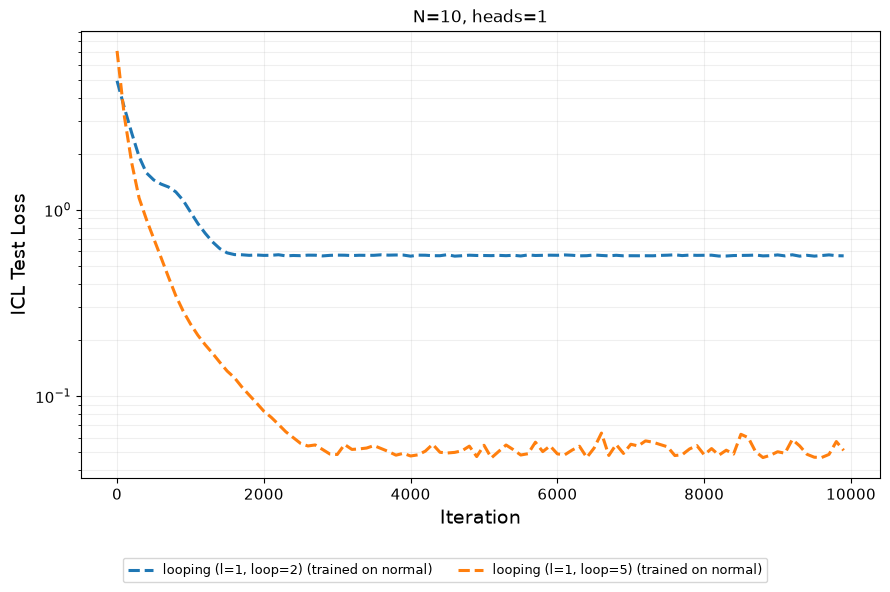

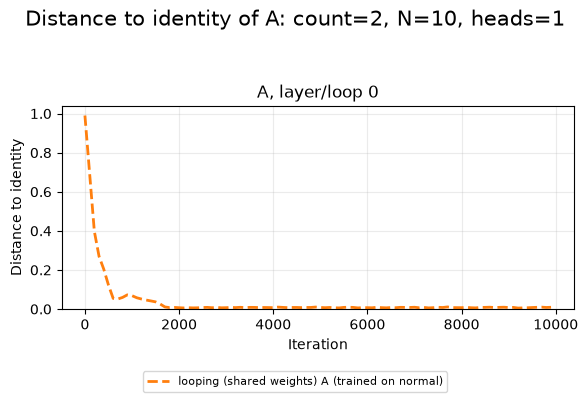

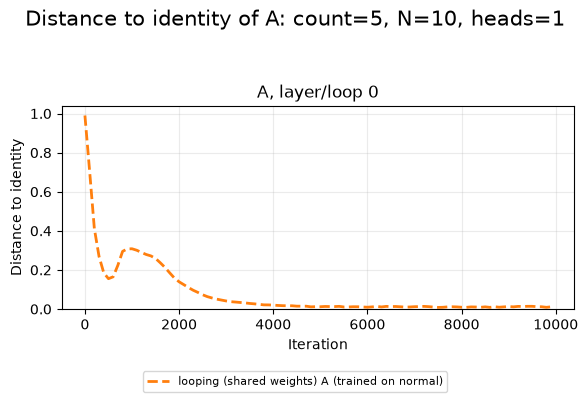

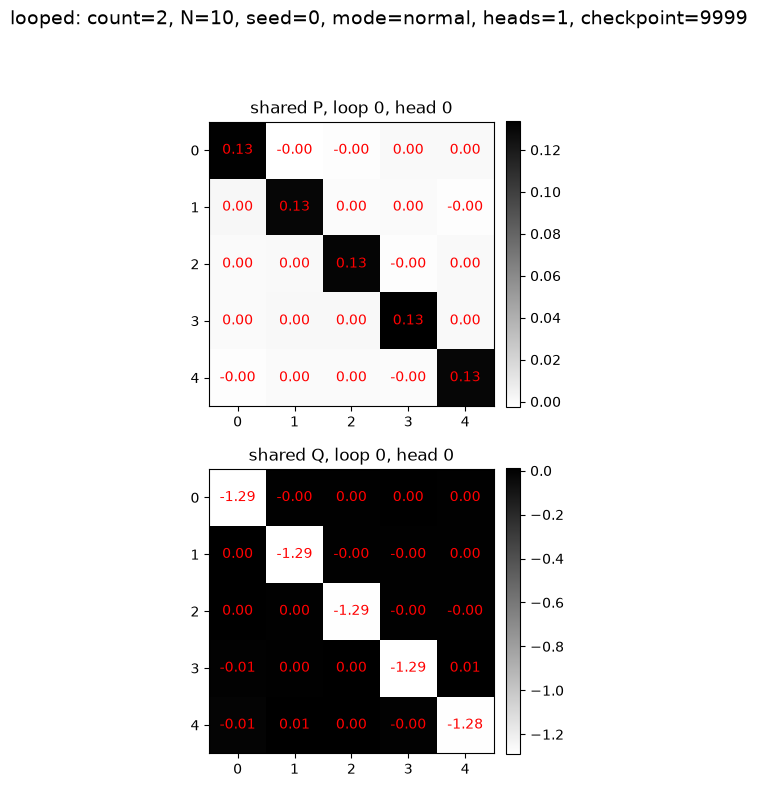

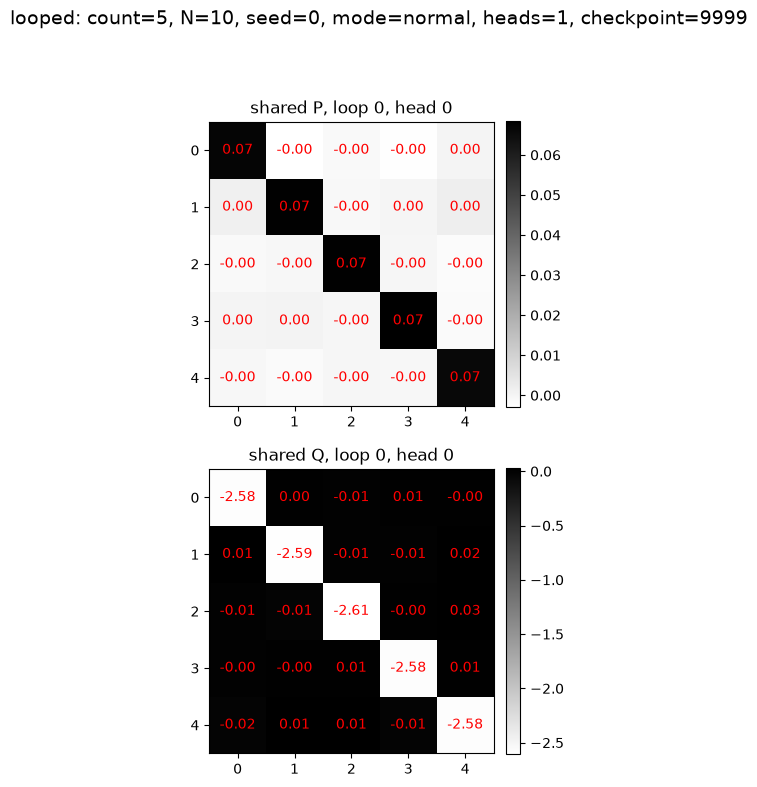

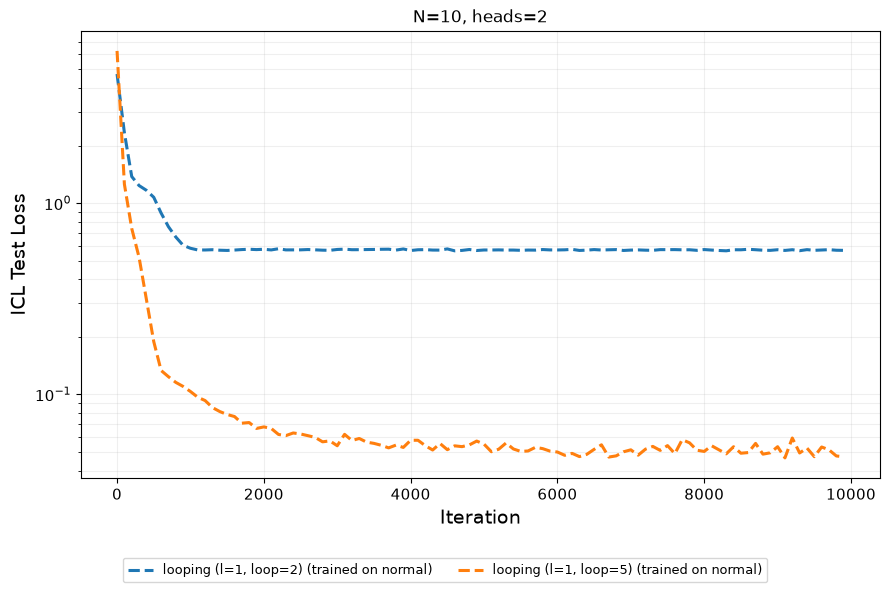

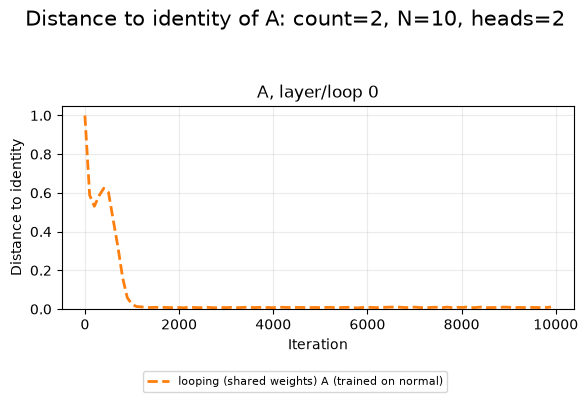

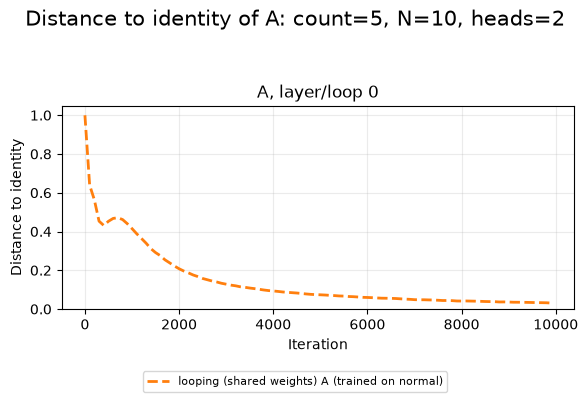

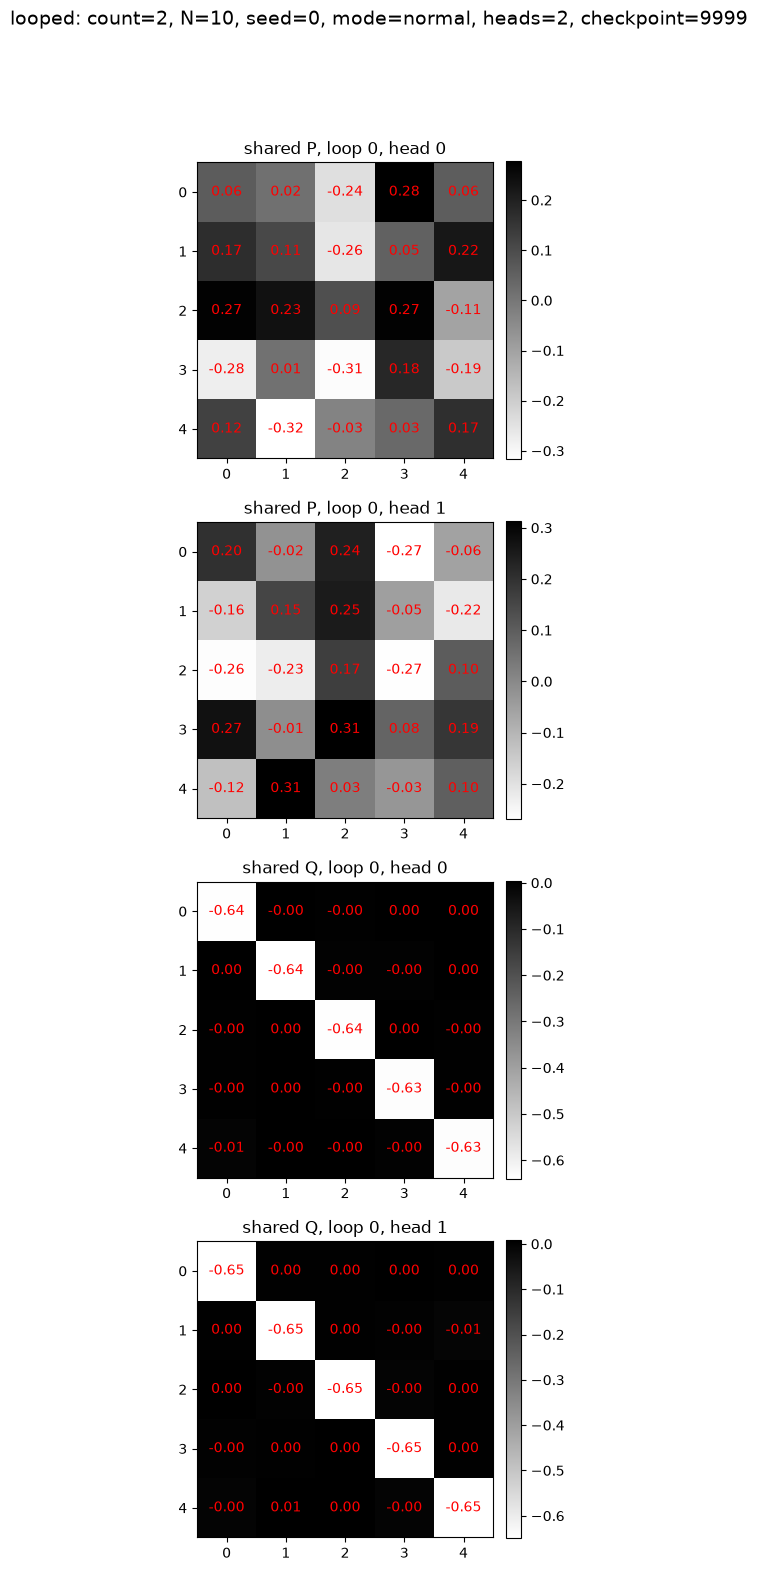

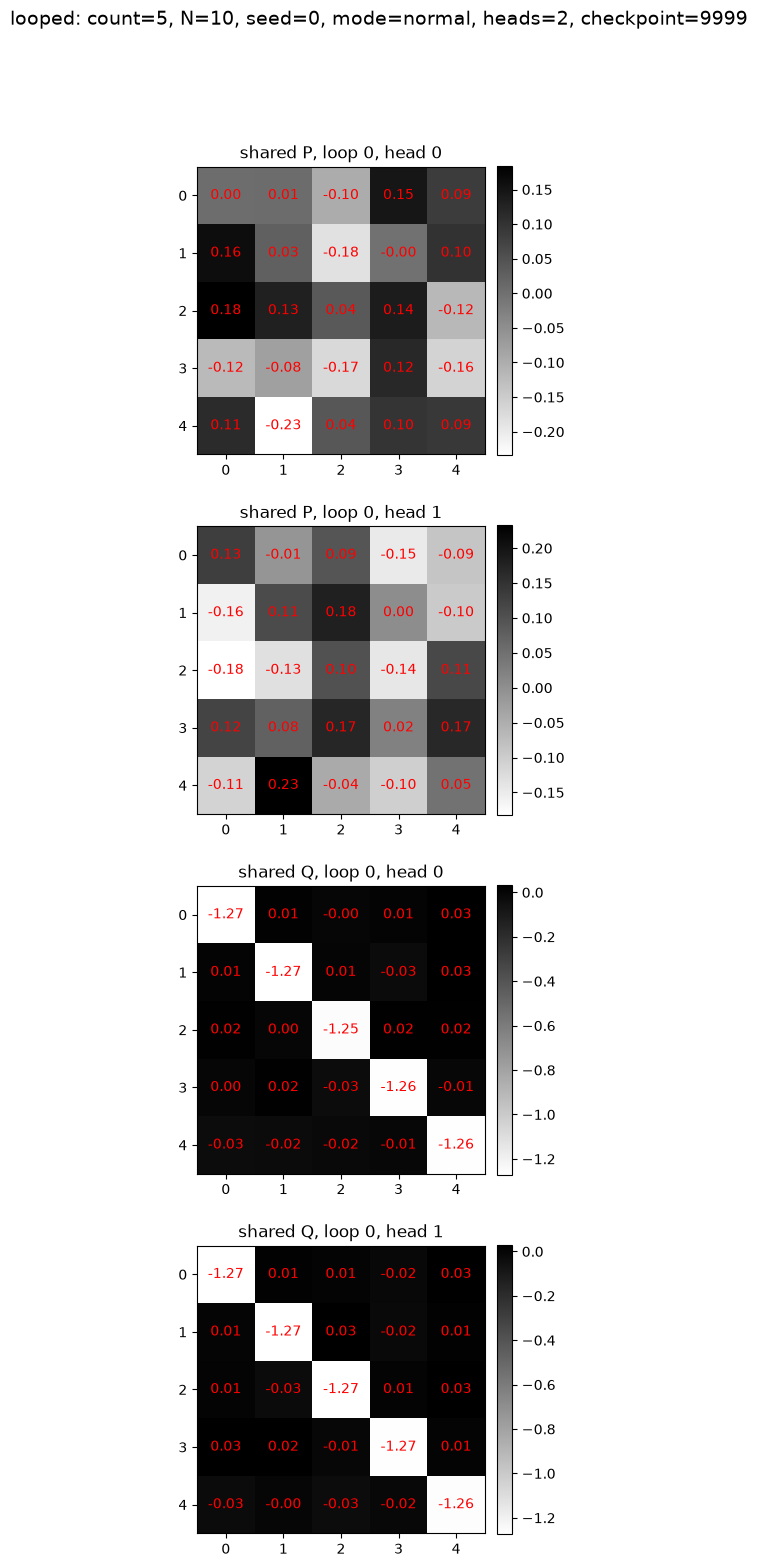

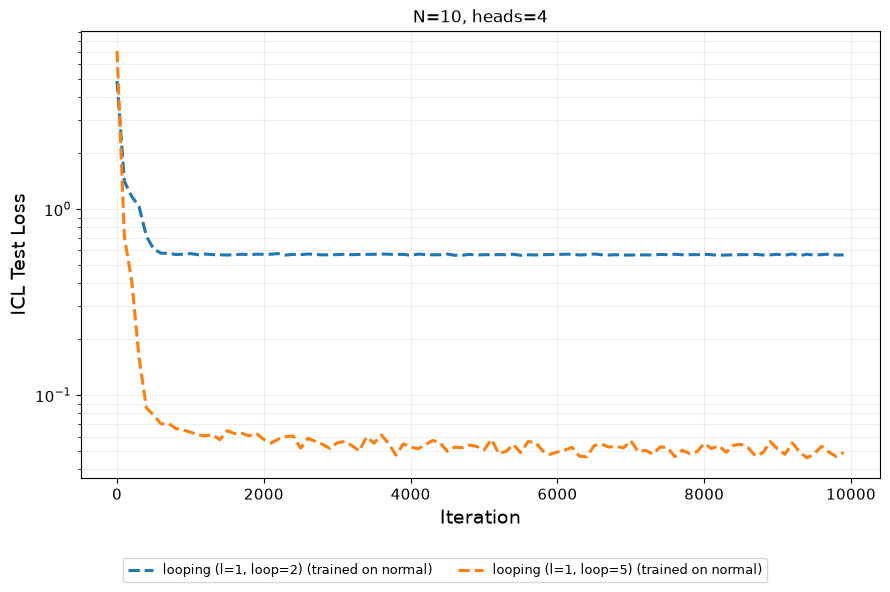

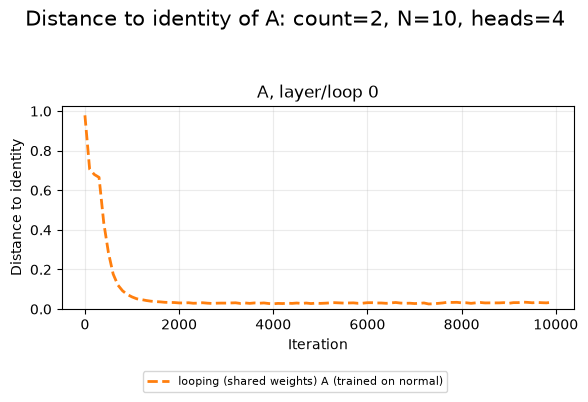

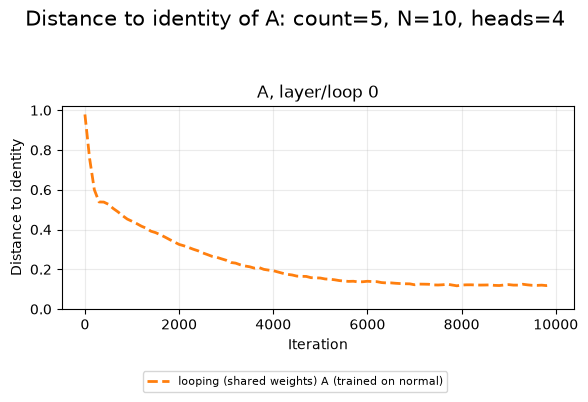

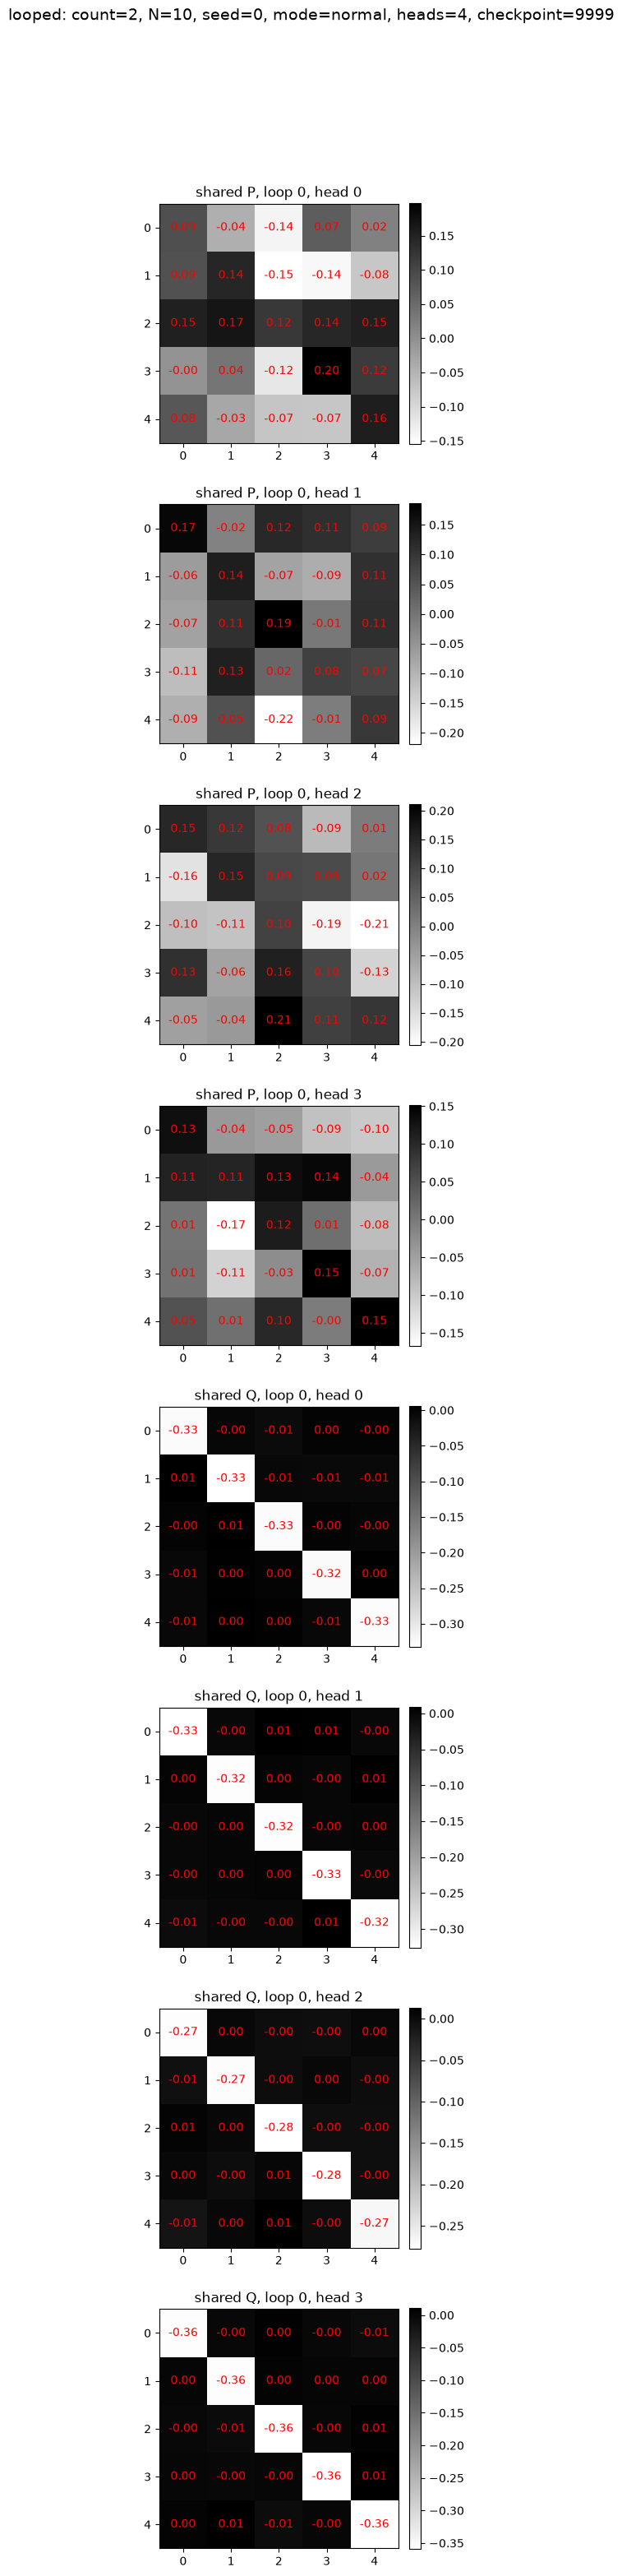

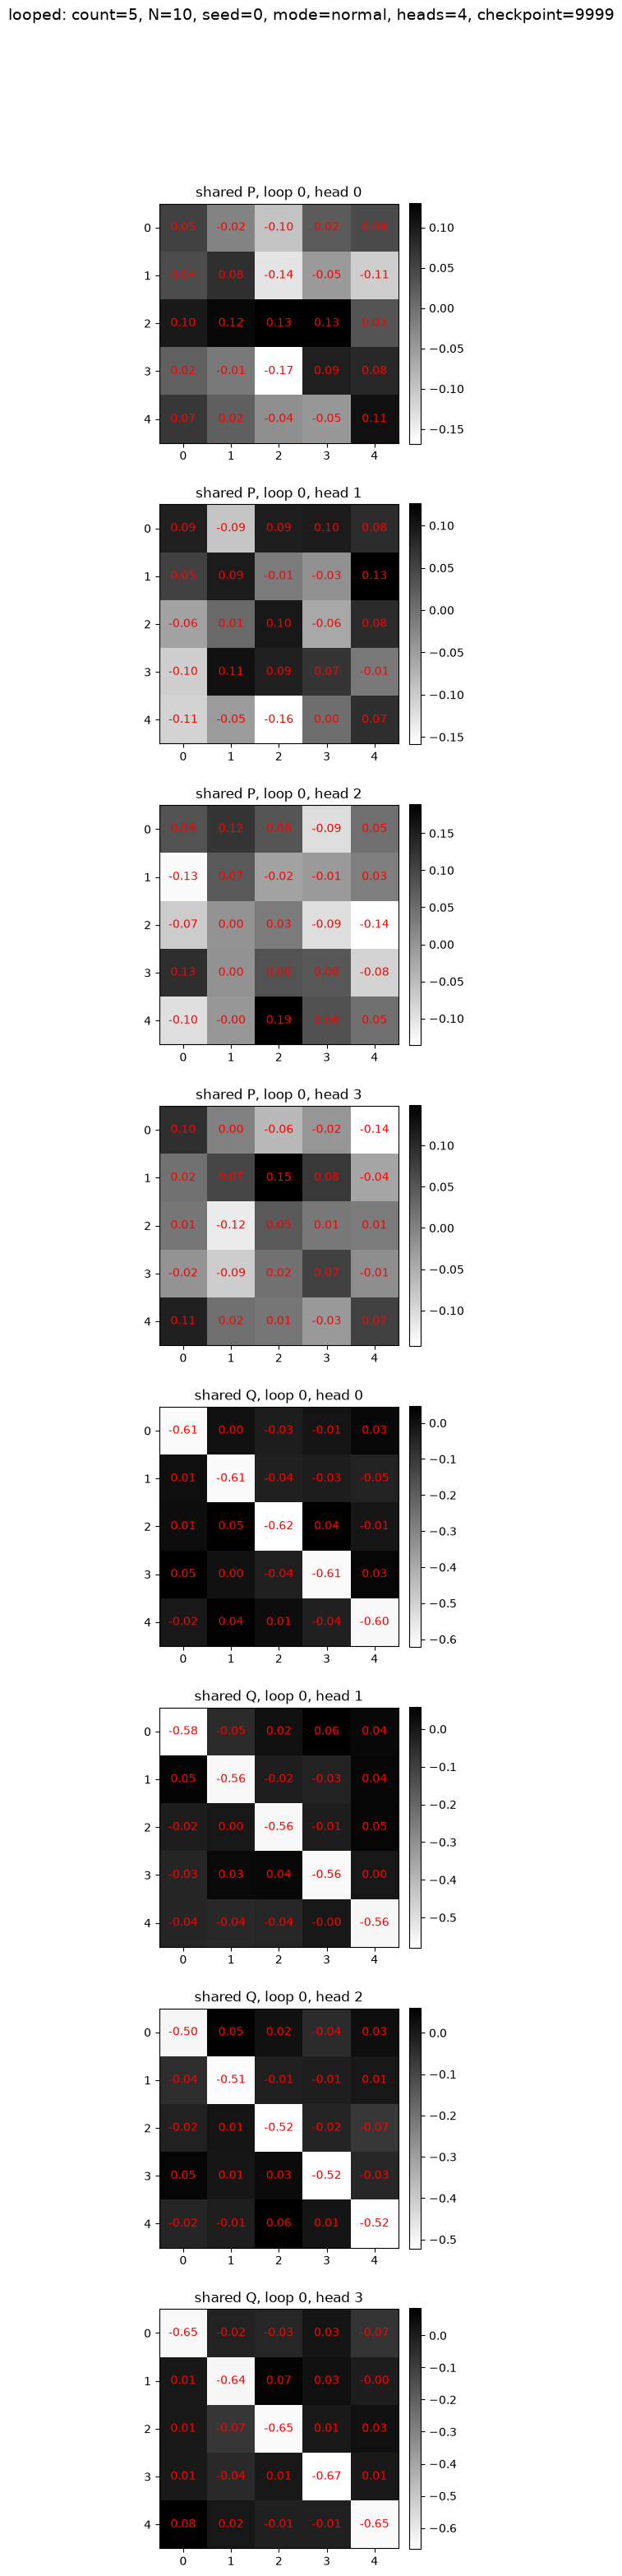

In [29]:
# Use the notebook's standard convergence, distance, and parameter plotting helpers.
multihead_plot_dir = os.path.join('figures', 'looped_multihead')
multihead_iterations = np.arange(0, max_iters, stride)

for head_count in multihead_head_counts:
    head_hist_dict = {
        key: history for key, history in multihead_hist_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_loss_dict = {
        key: losses for key, losses in multihead_loss_dict.items()
        if len(key) > 5 and key[5] == head_count
    }
    head_fig_dir = os.path.join(multihead_plot_dir, f'{head_count}_heads')
    os.makedirs(head_fig_dir, exist_ok=True)

    plot_loss_curves(
        head_loss_dict,
        multihead_loop_counts,
        multihead_model_types,
        multihead_iterations,
        fig_dir=head_fig_dir,
        filename='held_out_loss.pdf',
        seeds=multihead_seeds,
        head_count=head_count,
    )

    head_dist_dict = compute_dist_dict(
        head_hist_dict,
        multihead_iterations,
        n_head=head_count,
        hist_stride=hist_stride,
    )
    plot_dist_to_identity(
        head_dist_dict,
        multihead_loop_counts,
        multihead_iterations,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )

    plot_parameter_matrices(
        head_hist_dict,
        multihead_seeds[0],
        multihead_loop_counts,
        multihead_model_types,
        n_head=head_count,
        hist_stride=hist_stride,
        fig_dir=head_fig_dir,
        head_count=head_count,
    )


In [13]:
# Final experiment: repeat the layered/looped sweep with softmax attention.
# This uses the same seeds, counts, data mode, optimizer, training steps, and
# reusable loss/distance/parameter plotting helpers as the baseline experiment.
softmax_attention_type = 'softmax'
softmax_seeds = [0]
softmax_counts = [1, 2, 5, 10]
softmax_model_types = ['looped']
softmax_context_lengths = [N]
softmax_data_modes = [normal_data_mode]
softmax_iterations = np.arange(0, max_iters, stride)

softmax_fig_dir = os.path.join('figures', 'softmax_attention')
os.makedirs(softmax_fig_dir, exist_ok=True)
softmax_history_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_histories.pth')
softmax_results_file = os.path.join(
    cur_dir, f'softmax_attention_N{N}_d{d}_results.pth')

softmax_hist_dict = run_experiment_suite(
    seeds=softmax_seeds,
    n_layers_loops=softmax_counts,
    model_types=softmax_model_types,
    filename=softmax_history_file,
    context_lengths=softmax_context_lengths,
    data_modes=softmax_data_modes,
    head_counts=[n_head],
    attention_type=softmax_attention_type,
)
softmax_loss_dict = compute_loss_dict(
    softmax_hist_dict,
    test_seed=TEST_SEED,
    attention_type=softmax_attention_type,
)
softmax_dist_dict = compute_dist_dict(
    softmax_hist_dict,
    softmax_iterations,
    n_head=n_head,
    hist_stride=hist_stride,
)

torch.save(
    {
        'config': {
            'N': N, 'd': d, 'B': B, 'n_head': n_head,
            'attention_type': softmax_attention_type,
            'data_modes': softmax_data_modes,
            'seeds': softmax_seeds, 'counts': softmax_counts,
            'model_types': softmax_model_types,
            'alg': alg, 'lr': lr, 'clip_r': clip_r, 'var': var,
            'max_iters': max_iters, 'hist_stride': hist_stride,
            'stride': stride, 'test_seed': TEST_SEED,
        },
        'history_file': softmax_history_file,
        'hist_dict': softmax_hist_dict,
        'loss_dict': softmax_loss_dict,
        'distance_dict': softmax_dist_dict,
        'iterations': softmax_iterations,
    },
    softmax_results_file,
)
print(f'Saved softmax-attention experiment results to {softmax_results_file}')

Run 1/4: seed=0, count=1, type=looped, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=softmax
iter 0 | Loss: 4.581579208374023 | time: 0.0037674903869628906 | gradnorm: 0.24219128489494324
iter 1 | Loss: 4.262875080108643 | time: 0.002960205078125 | gradnorm: 0.2497432678937912
iter 2 | Loss: 4.506096839904785 | time: 0.0028362274169921875 | gradnorm: 0.2598385512828827
iter 3 | Loss: 4.317121505737305 | time: 0.004277467727661133 | gradnorm: 0.2515520751476288
iter 4 | Loss: 4.376910209655762 | time: 0.004574775695800781 | gradnorm: 0.2546485364437103
iter 100 | Loss: 4.34943151473999 | time: 0.002773284912109375 | gradnorm: 0.2729487121105194
iter 200 | Loss: 4.419742584228516 | time: 0.0027611255645751953 | gradnorm: 0.25923097133636475
iter 300 | Loss: 4.488523483276367 | time: 0.0027718544006347656 | gradnorm: 0.2458757758140564
iter 400 | Loss: 4.3228373527526855 | time: 0.0036818981170654297 | gradnorm: 0.216259

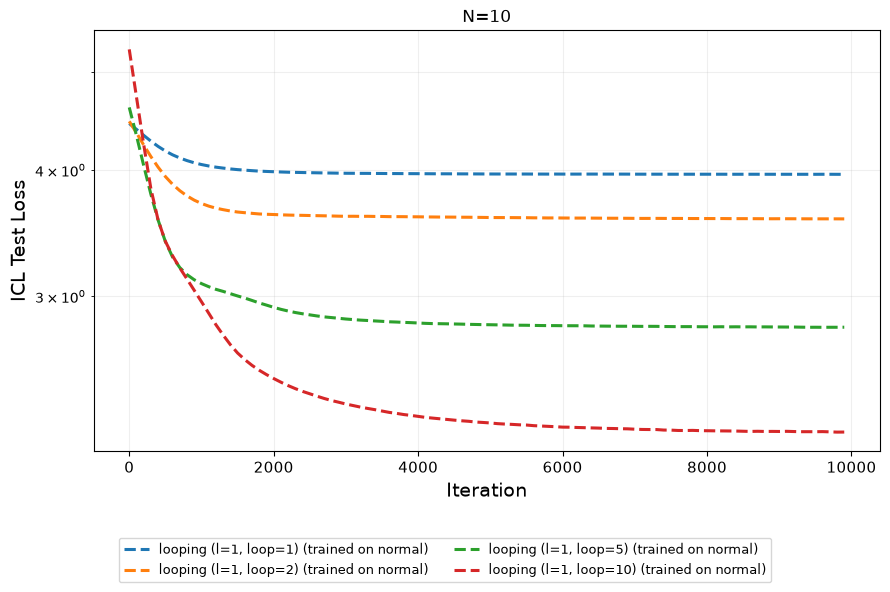

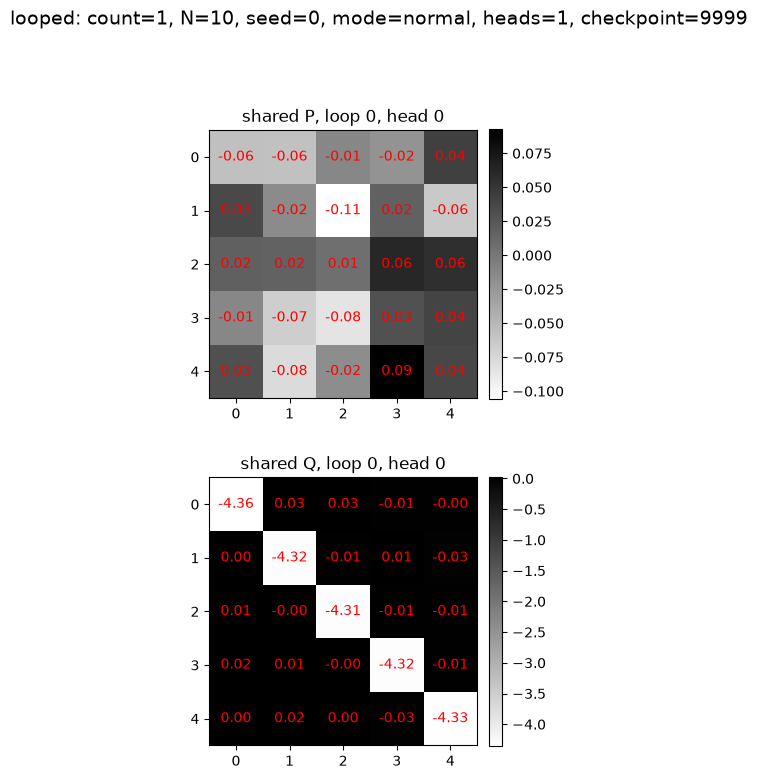

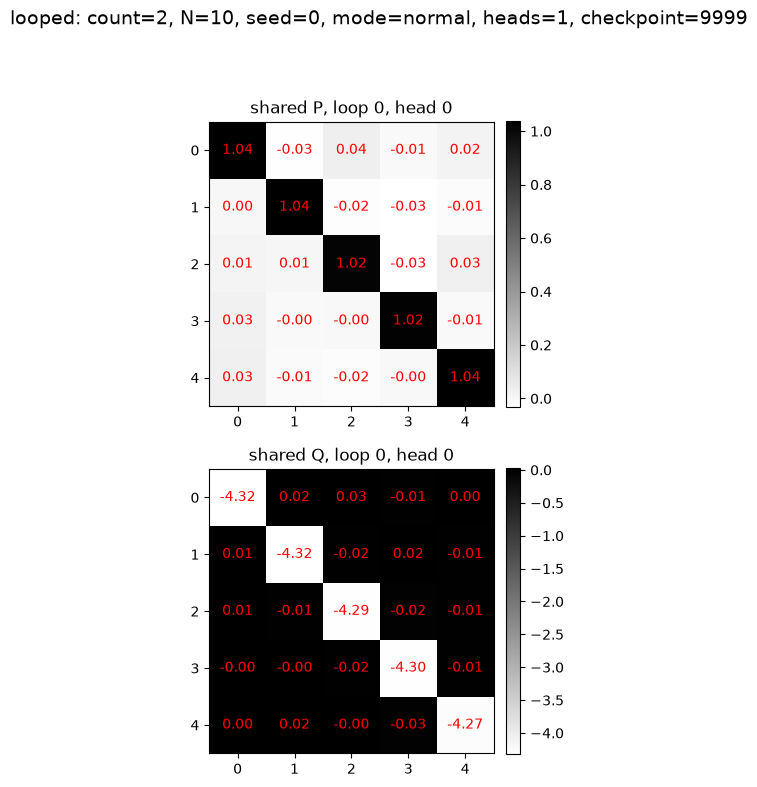

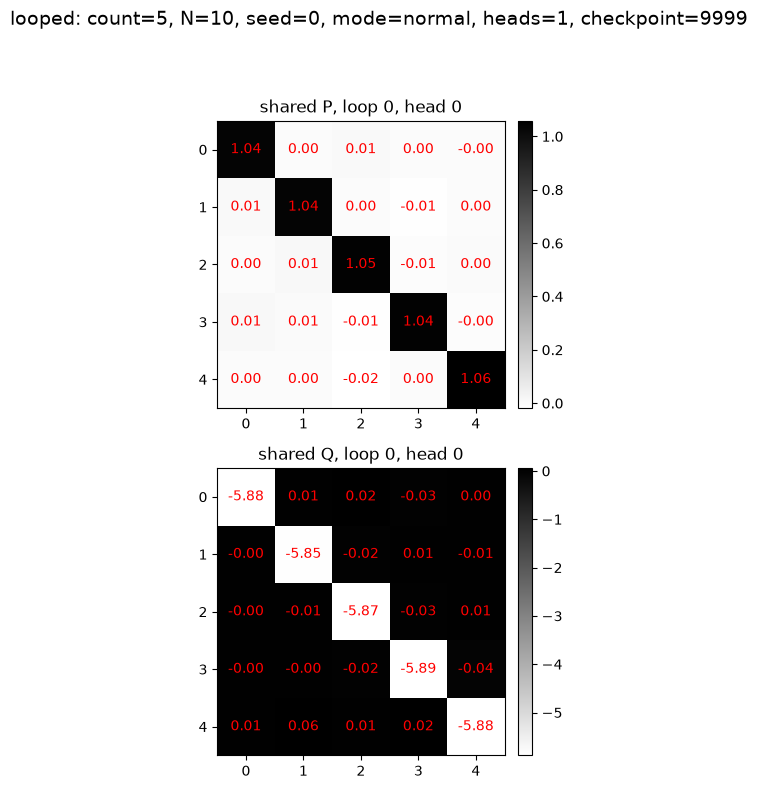

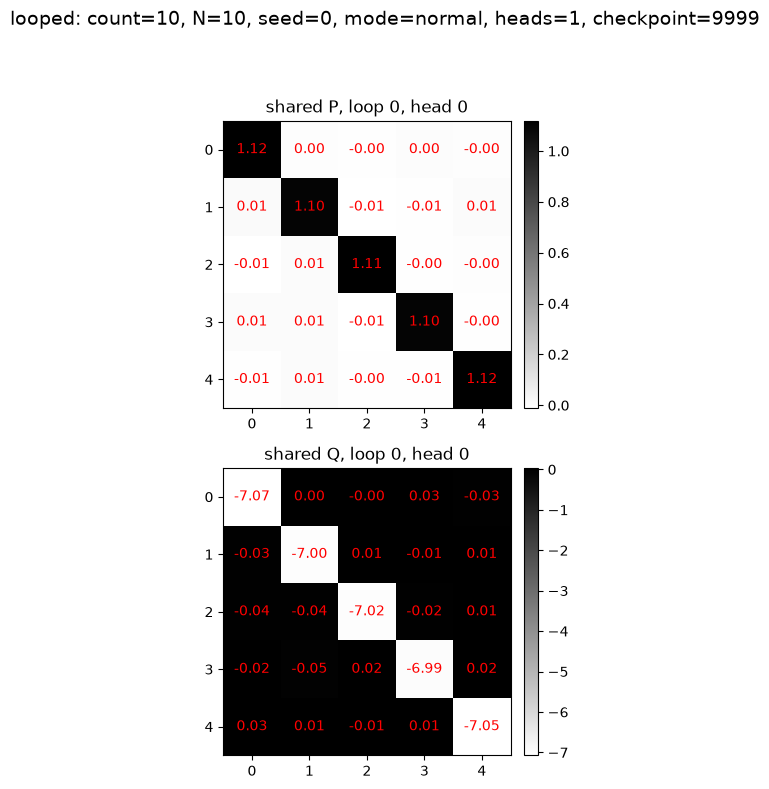

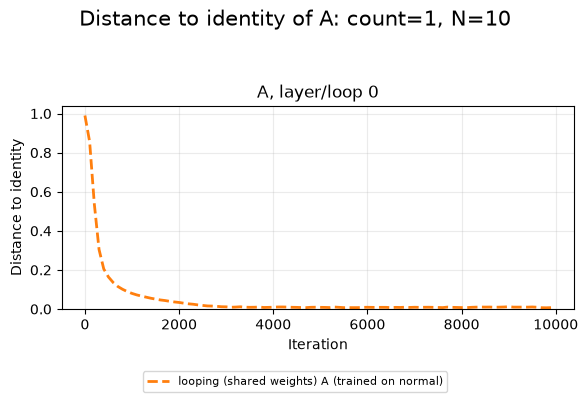

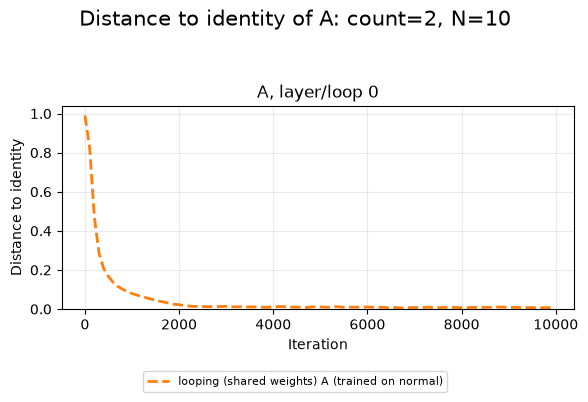

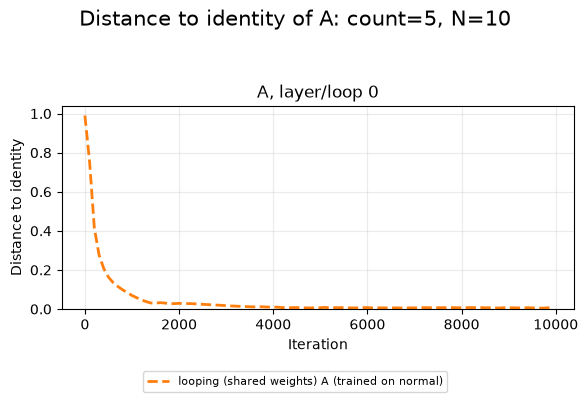

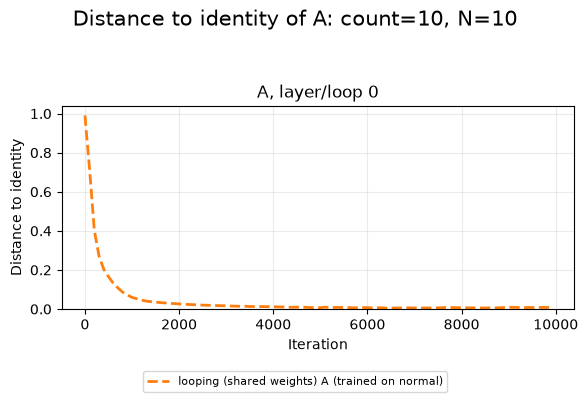

In [14]:
plot_loss_curves(
    softmax_loss_dict,
    softmax_counts,
    softmax_model_types,
    softmax_iterations,
    fig_dir=softmax_fig_dir,
    filename='softmax_test_loss_layered_vs_looped.pdf',
)
plot_parameter_matrices(
    softmax_hist_dict,
    softmax_seeds[0],
    softmax_counts,
    softmax_model_types,
    n_head,
    hist_stride=hist_stride,
    fig_dir=softmax_fig_dir,
)
plot_dist_to_identity(
    softmax_dist_dict,
    softmax_counts,
    softmax_iterations,
    fig_dir=softmax_fig_dir,
)

Testing: (0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 1, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evaluated checkpoint (0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax') through 50 loops.
Testing: (0, 10, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1, 'softmax')
Evalua

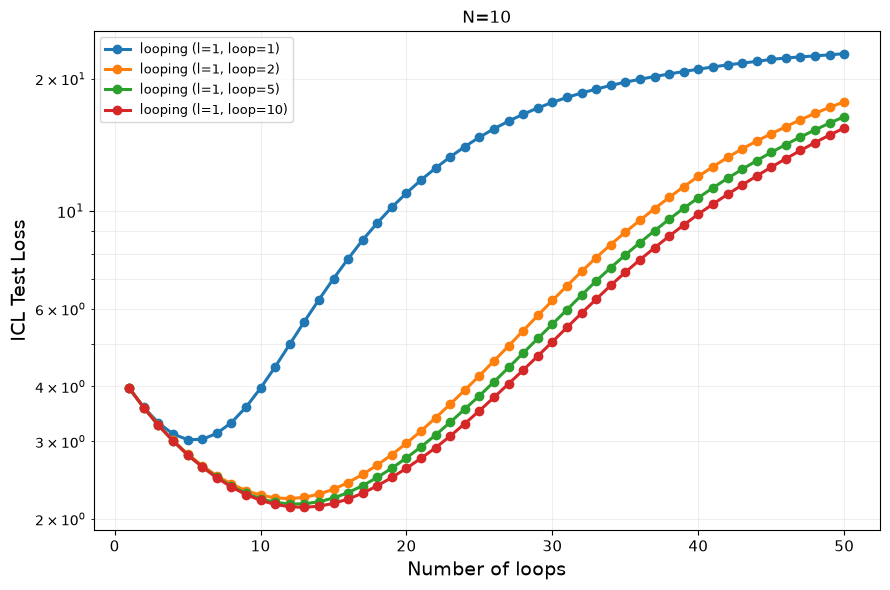

Saved softmax loop-count results to log/softmax_attention_loop_count_N10_d5_results.pth


In [22]:
# Evaluate final softmax looped checkpoints with 1 through 50 inference loops.
softmax_looped_hist_dict = {
    key: history
    for key, history in softmax_hist_dict.items()
    if key[2] == 'looped' and key[-1] == 'softmax'
}

softmax_max_loops = 50
softmax_loop_loss_dict = compute_looped_loss_by_loop_count(
    softmax_looped_hist_dict,
    max_loops=softmax_max_loops,
    test_seed=TEST_SEED,
    attention_type='softmax',
)

softmax_loop_results_file = os.path.join(
    cur_dir, f'softmax_attention_loop_count_N{N}_d{d}_results.pth',
)
torch.save({
    'max_loops': softmax_max_loops,
    'test_seed': TEST_SEED,
    'attention_type': 'softmax',
    'loss_dict': softmax_loop_loss_dict,
}, softmax_loop_results_file)

plot_loop_loss_curves(
    softmax_loop_loss_dict,
    n_layers_loops=softmax_counts,
    loop_counts=range(1, softmax_max_loops + 1),
    fig_dir=softmax_fig_dir,
    filename='softmax_test_loss_vs_loop_count.pdf',
)
print(f'Saved softmax loop-count results to {softmax_loop_results_file}')